# Football Player-Role Classification — Phase 1

This experiment uses SoccerNet game-state annotations to prepare player crops, train role classifiers, and evaluate their performance on held-out match data.


## Dataset preparation

Locate the source images and game-state annotations, establish the working directories, and prepare the data used for frame extraction and role classification.


## Source data and dependencies

Install the required packages and obtain the SoccerNet SN-GSR-2025 training archive. Extract the image and annotation files, identify `Labels-GameState.json`, and set the dataset root for the remaining steps.


In [1]:
# Kaggle: install small missing dependencies (torch/torchvision are preinstalled in most GPU images)
import sys, subprocess, importlib.util
required = {'huggingface_hub':'huggingface_hub', 'wandb':'wandb', 'datasets':'datasets'}
missing = [pip for module,pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Kaggle setup: optional packages checked; missing installed:', missing)


Kaggle setup: optional packages checked; missing installed: []


In [2]:

# ============================================================
# SoccerNet GSR 2025 — Download from Hugging Face for Kaggle
# ============================================================

%pip install -q huggingface_hub hf_xet

from huggingface_hub import hf_hub_download
from pathlib import Path
import zipfile

REPO_ID = "SoccerNet/SN-GSR-2025"

DATA_DIR = Path("/kaggle/working/soccer_gsr")
EXTRACT_TO = DATA_DIR / "extracted"

DATA_DIR.mkdir(parents=True, exist_ok=True)
EXTRACT_TO.mkdir(parents=True, exist_ok=True)

# Check whether data is already extracted
label_files = list(EXTRACT_TO.rglob("Labels-GameState.json"))

if label_files:
    print("Dataset already extracted. Skipping download.")
else:
    print("Downloading SoccerNet train.zip from Hugging Face...")

    zip_path = hf_hub_download(
        repo_id=REPO_ID,
        filename="train.zip",
        repo_type="dataset",
        local_dir=str(DATA_DIR)
    )

    print("Download completed:", zip_path)

    print("Extracting dataset...")

    with zipfile.ZipFile(zip_path, "r") as zf:
        for member in zf.infolist():
            target = (EXTRACT_TO / member.filename).resolve()
            if not target.is_relative_to(EXTRACT_TO.resolve()):
                raise ValueError(f"Unsafe ZIP path: {member.filename}")
        zf.extractall(EXTRACT_TO)

    print("Extraction completed.")

# Define the dataset path for Phase 1
GSR_ROOT = EXTRACT_TO

# Verify annotations
label_files = sorted(GSR_ROOT.rglob("Labels-GameState.json"))

print("\nGSR_ROOT:", GSR_ROOT)
print("Total annotation files:", len(label_files))

if not label_files:
    raise FileNotFoundError(
        "No Labels-GameState.json files found after extraction."
    )

print("Example:", label_files[0])


train.zip: reconstructing file:   0%|          |  0.00B / 9.76GB            

train.zip: downloading bytes:           |  0.00B            

Download completed: /kaggle/working/soccer_gsr/train.zip
Extracting dataset...
Extraction completed.

GSR_ROOT: /kaggle/working/soccer_gsr/extracted
Total annotation files: 57
Example: /kaggle/working/soccer_gsr/extracted/SNGS-060/Labels-GameState.json


In [3]:
from pathlib import Path
import os, json, random, hashlib, shutil, sys, platform, time, gc, math, importlib.metadata
from collections import Counter, defaultdict
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib.pyplot as plt, cv2
from PIL import Image, ImageOps, ImageDraw
from tqdm.auto import tqdm
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_fscore_support, accuracy_score, f1_score)
from sklearn.cluster import KMeans
from scipy.optimize import linear_sum_assignment
from scipy.stats import beta
import torch, torchvision, wandb
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import yaml
print('Python:',sys.version.split()[0], '| torch:',torch.__version__, '| torchvision:',torchvision.__version__)

Python: 3.13.16 | torch: 2.11.0+cu130 | torchvision: 0.26.0+cu130


## Experiment configuration and reproducibility

Define the random seed, frame sampling rate, crop dimensions, data-split proportions, training hyperparameters, and evaluation thresholds. Record the configuration and package environment, and select the available compute device.


In [4]:
CFG = dict(
    gsr_root=str(GSR_ROOT), output_root='/kaggle/working/football_project_outputs',
    seed=42, image_size=224, frame_step=25, max_clips=48, max_frames_per_clip=35,
    max_crop_per_class=3500, min_crop_side=24, min_independent_matches=3,
    test_fraction=0.20, val_fraction=0.20, batch_size=32, num_workers=0,
    scratch_epochs=16, frozen_epochs=10, full_epochs=10, patience=4,
    scratch_lr=1e-3, frozen_lr=1e-3, full_lr=1e-4,
    weight_decay=1e-4, grad_clip=1.0, wandb_project='football-capstone-ai251p',
    wandb_mode='offline', prototype_train_per_class=90, prototype_val_per_class=90,
    detector_epochs=35, detector_imgsz=960, detector_batch=8,
    segmentation_epochs=12, segmentation_batch=4, segmentation_size=(512,288),
    audit_n=120, n_ball_review_frames=450,
    ball_min_conf=0.65, ball_min_area_ratio=0.000008, ball_max_area_ratio=0.004,
    ball_min_aspect=0.40, ball_max_aspect=2.5,
    # Preset BEFORE results; illustrative project acceptance criteria (adjust before experiments).
    min_role_macro_f1=0.75, min_ball_recall=0.70, min_pitch_mean_iou=0.55,
    max_p95_latency_ms=300, # device-specific target; clearly report backend
)
SEED=CFG['seed']
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available():
    DEVICE=torch.device('cuda');torch.cuda.manual_seed_all(SEED)
elif getattr(torch.backends,'mps',None) and torch.backends.mps.is_available():
    DEVICE=torch.device('mps')
else: DEVICE=torch.device('cpu')
ROOT=Path(CFG['gsr_root'])
RUN_ID=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
OUT=Path(CFG['output_root'])/RUN_ID
CACHE=OUT/'data_cache'; REVIEW=OUT/'quality_checks'
for p in [OUT,CACHE,REVIEW]: p.mkdir(parents=True,exist_ok=True)
(OUT/'config.json').write_text(json.dumps(CFG,indent=2))
PACKAGES=['torch','torchvision','numpy','pandas','Pillow','opencv-python','scikit-learn','scipy',
          'matplotlib','wandb','ultralytics','segmentation-models-pytorch','onnx','onnxruntime','fastapi']
(OUT/'requirements-lock.txt').write_text('\n'.join(
    f'{p}=={importlib.metadata.version(p)}' for p in PACKAGES if importlib.metadata.packages_distributions() and
    (lambda a: a is not None)(importlib.util.find_spec({'Pillow':'PIL','opencv-python':'cv2','scikit-learn':'sklearn',
    'segmentation-models-pytorch':'segmentation_models_pytorch'}.get(p,p)))
)+'\n')
(OUT/'environment.json').write_text(json.dumps({'python':sys.version,'platform':platform.platform(),
                                               'device':str(DEVICE)},indent=2))
print('Device:', DEVICE, '| Dataset:',CFG['gsr_root'], '| Outputs:',CFG['output_root'])

Device: cuda | Dataset: /kaggle/working/soccer_gsr/extracted | Outputs: /kaggle/working/football_project_outputs


### M1 — Annotation inventory

Find the available `Labels-GameState.json` files and inspect their locations and structure before processing frames.


In [5]:
from pathlib import Path
ROOT = Path(CFG['gsr_root'])
if not ROOT.is_dir():
    raise FileNotFoundError(f'Expected dataset folder: {ROOT}. Attach/extract SoccerNet GSR using the Kaggle setup cell.')
json_files = sorted(ROOT.rglob('Labels-GameState.json'))
print('Dataset root:', ROOT)
print('Found annotation files:', len(json_files))
print('Sequence examples:', [str(p.parent.relative_to(ROOT)) for p in json_files[:8]])
if not json_files:
    raise FileNotFoundError('No Labels-GameState.json found. Attach/extract the GSR dataset using the Kaggle setup cell.')

Dataset root: /kaggle/working/soccer_gsr/extracted
Found annotation files: 57
Sequence examples: ['SNGS-060', 'SNGS-061', 'SNGS-062', 'SNGS-063', 'SNGS-064', 'SNGS-065', 'SNGS-066', 'SNGS-067']


### M1 — Annotation visualization

Display representative frames with annotated objects to inspect image dimensions, object sizes, and annotation coverage.


Source: SNGS-060/Labels-GameState.json
Keys: ['info', 'images', 'annotations', 'categories']
Info: {
  "version": "1.3",
  "game_id": "4",
  "id": "060",
  "num_tracklets": "26",
  "action_position": "895",
  "action_class": "Kick-off",
  "visibility": "visible",
  "game_time_start": "1 - 00:00",
  "game_time_stop": "1 - 00:30",
  "clip_start": "0",
  "clip_stop": "30000",
  "name": "SNGS-060",
  "im_dir": "img1",
  "frame_rate": 25,
  "seq_length": 750,
  "im_ext": ".jpg"
}
Frames: 750 Objects: 14290
Sample image record: {"is_labeled": true, "image_id": "1060000001", "file_name": "000001.jpg", "height": 1080, "width": 1920, "has_labeled_person": true, "has_labeled_pitch": true, "has_labeled_camera": true, "ignore_regions_y": [], "ignore_regions_x": []}
Sample object: {"id": "1060000001", "image_id": "1060000001", "track_id": 1, "supercategory": "object", "category_id": 1, "attributes": {"role": "player", "jersey": "10", "team": "left"}, "bbox_image": {"x": 914, "y": 855, "x_center": 9

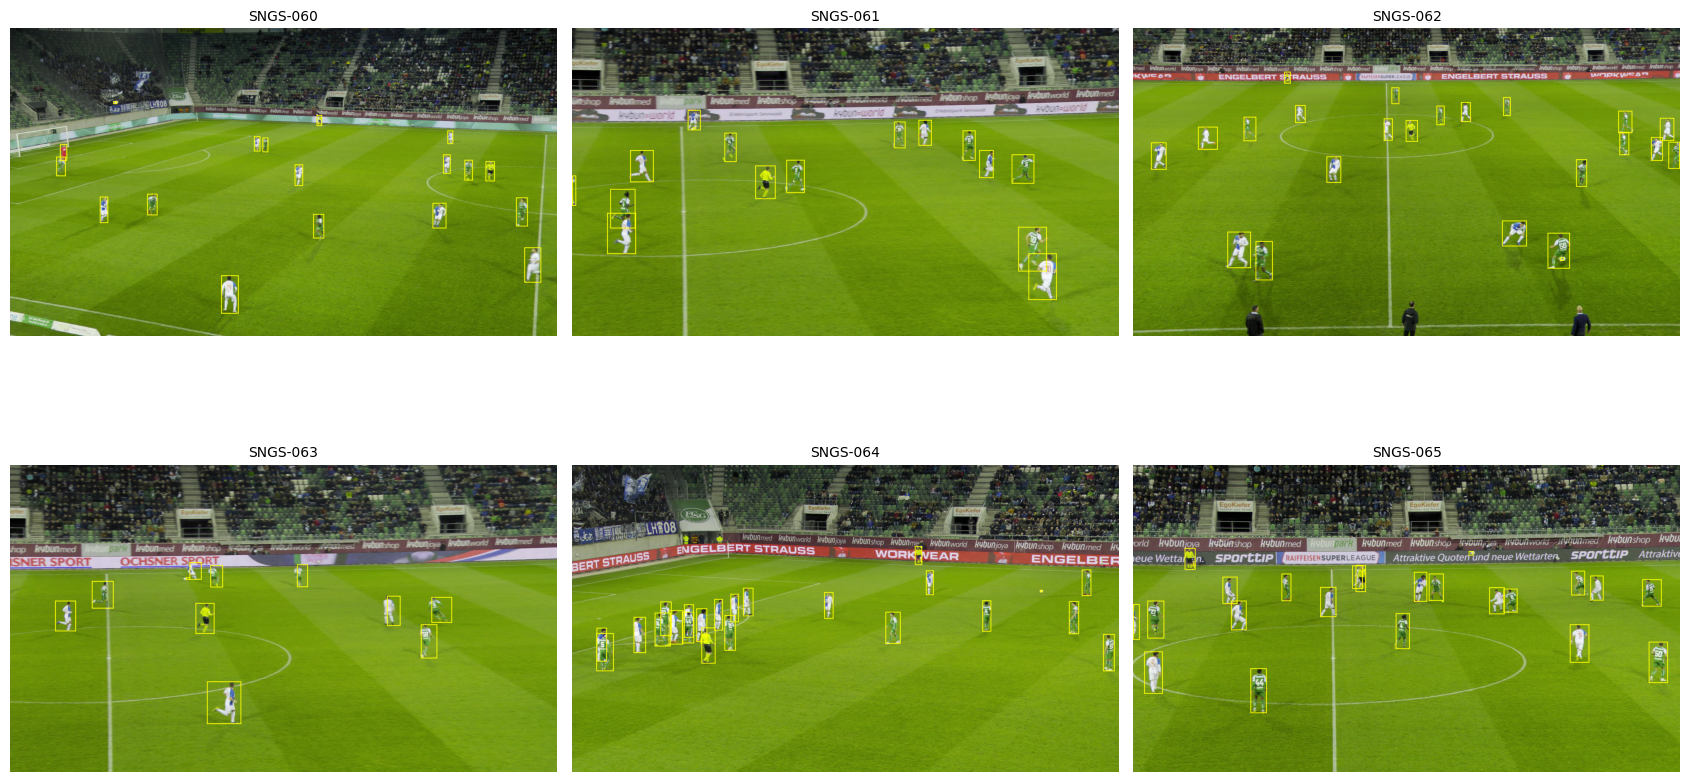

Displayed 6 frames from different sequences.


In [6]:
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display
import matplotlib.pyplot as plt
from collections import defaultdict
import json, cv2

sample_path = json_files[0]
with sample_path.open(encoding='utf-8') as handle:
    sample_doc = json.load(handle)
print('Source:', sample_path.relative_to(ROOT))
print('Keys:', list(sample_doc))
print('Info:', json.dumps(sample_doc.get('info', {}), ensure_ascii=False, indent=2)[:1400])
print('Frames:', len(sample_doc.get('images', [])), 'Objects:', len(sample_doc.get('annotations', [])))
print('Sample image record:', json.dumps(sample_doc.get('images', [None])[0], ensure_ascii=False)[:1000])
print('Sample object:', json.dumps(sample_doc.get('annotations', [None])[0], ensure_ascii=False)[:1200])

def preview_image(seq_dir, info, rec, ordinal):
    name = str(rec.get('file_name', ''))
    for path in (seq_dir/name, seq_dir/str(info.get('im_dir') or 'img1')/name, seq_dir/'img1'/name):
        if path.is_file():
            with Image.open(path) as im:
                return ImageOps.exif_transpose(im).convert('RGB').copy()
    videos = sorted([*seq_dir.glob('*.mp4'), *seq_dir.glob('*.mkv')])
    if videos:
        capture = cv2.VideoCapture(str(videos[0]))
        frame_no = rec.get('frame_id')
        if frame_no is None:
            frame_no = ordinal + 1
        try:
            capture.set(cv2.CAP_PROP_POS_FRAMES, max(0, int(frame_no)-1))
            ok, bgr = capture.read()
        finally:
            capture.release()
        if ok:
            return Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    return None

fig, axs = plt.subplots(2, 3, figsize=(17, 10))
shown = 0
for source in json_files:
    if shown >= 6: break
    with source.open(encoding='utf-8') as f: doc = json.load(f)
    records = doc.get('images', [])
    if not records: continue
    ann_index = defaultdict(list)
    for ann in doc.get('annotations', []): ann_index[str(ann.get('image_id'))].append(ann)
    ordinal = min(len(records)-1, max(0, len(records)//3))
    record = records[ordinal]
    rgb = preview_image(source.parent, doc.get('info', {}), record, ordinal)
    if rgb is None: continue
    drawer = ImageDraw.Draw(rgb)
    for ann in ann_index.get(str(record.get('id', record.get('image_id'))), []):
        bbox = ann.get('bbox_image') or {}
        if isinstance(bbox, dict) and all(k in bbox for k in ('x', 'y', 'w', 'h')):
            x, y, w, h = (float(bbox[k]) for k in ('x','y','w','h'))
            drawer.rectangle((x, y, x+w, y+h), outline='yellow', width=3)
    ax = axs.flat[shown]
    ax.imshow(rgb)
    ax.set_title(str(source.parent.relative_to(ROOT)), fontsize=10)
    ax.axis('off')
    shown += 1
for ax in list(axs.flat)[shown:]: ax.axis('off')
plt.tight_layout()
plt.show()
print(f'Displayed {shown} frames from different sequences.')
if not shown: print('No frame image or video could be decoded; inspect the local sequence structure.')

## M1 — Annotation structure and match identifiers

Read game-state annotations and sequence metadata. Retain source match identifiers so frames from the same match can be grouped during dataset splitting.


In [7]:
json_files = sorted(ROOT.rglob('Labels-GameState.json'))
if not json_files:
    raise FileNotFoundError('No Labels-GameState.json under configured Kaggle GSR_ROOT')
print('Number of sequences:',len(json_files))
print('First source:',json_files[0].relative_to(ROOT))
with json_files[0].open(encoding='utf-8') as f: sample=json.load(f)
print('Top-level:',list(sample))
print('Info fields:', sample.get('info',{}))
print('First image:',sample.get('images',[None])[0])
print('First annotation:',sample.get('annotations',[None])[0])
assert {'images','annotations'}.issubset(sample), 'Unexpected JSON schema; inspect source before proceeding.'

Number of sequences: 57
First source: SNGS-060/Labels-GameState.json
Top-level: ['info', 'images', 'annotations', 'categories']
Info fields: {'version': '1.3', 'game_id': '4', 'id': '060', 'num_tracklets': '26', 'action_position': '895', 'action_class': 'Kick-off', 'visibility': 'visible', 'game_time_start': '1 - 00:00', 'game_time_stop': '1 - 00:30', 'clip_start': '0', 'clip_stop': '30000', 'name': 'SNGS-060', 'im_dir': 'img1', 'frame_rate': 25, 'seq_length': 750, 'im_ext': '.jpg'}
First image: {'is_labeled': True, 'image_id': '1060000001', 'file_name': '000001.jpg', 'height': 1080, 'width': 1920, 'has_labeled_person': True, 'has_labeled_pitch': True, 'has_labeled_camera': True, 'ignore_regions_y': [], 'ignore_regions_x': []}
First annotation: {'id': '1060000001', 'image_id': '1060000001', 'track_id': 1, 'supercategory': 'object', 'category_id': 1, 'attributes': {'role': 'player', 'jersey': '10', 'team': 'left'}, 'bbox_image': {'x': 914, 'y': 855, 'x_center': 941.5, 'y_center': 941.0,

### M1 — Frame sampling and role annotations

Sample frames at a stride of 25 and extract person bounding boxes with role labels: `player`, `goalkeeper`, and `referee`. Preserve each sample's frame and match identifiers.


In [8]:
ROLE_NAMES=['player','goalkeeper','referee']
ROLE_TO_ID={v:i for i,v in enumerate(ROLE_NAMES)}
DET_NAMES=['player','goalkeeper','referee','ball']

def clean_role(role):
    value=str(role or '').lower().strip()
    if 'referee' in value: return 'referee'
    if 'goalkeeper' in value: return 'goalkeeper'
    if value=='player': return 'player'
    return None

def safe_id(s):
    return ''.join(c if c.isalnum() or c in ('-','_') else '_' for c in str(s))

def video_for_seq(seq_dir):
    options=sorted(list(seq_dir.glob('*.mp4'))+list(seq_dir.glob('*.mkv')))
    return options[0] if options else None

def load_frame(seq_dir, info, image_record, ordinal, cap=None):
    name=str(image_record.get('file_name',''))
    paths=[seq_dir/name,seq_dir/str(info.get('im_dir') or 'img1')/name,seq_dir/'img1'/name]
    for p in paths:
        if p.is_file():
            with Image.open(p) as im: return ImageOps.exif_transpose(im).convert('RGB').copy()
    if cap is None: raise FileNotFoundError('No frame image or MP4 found for '+str(seq_dir))
    # GSR frame order is the authoritative index. Confirm alignment in visual audit below.
    cap.set(cv2.CAP_PROP_POS_FRAMES,max(0,int(image_record.get('frame_id') or ordinal+1)-1))
    ok,bgr=cap.read()
    if not ok: raise IOError(f'Could not decode ordinal frame {ordinal} in {seq_dir}')
    return Image.fromarray(cv2.cvtColor(bgr,cv2.COLOR_BGR2RGB))

frames, boxes, errors, clip_metadata=[],[],[],[]
for source in tqdm(json_files[:CFG['max_clips']],desc='Extract annotated frames'):
    with source.open() as f: doc=json.load(f)
    info=doc.get('info',{})
    match_id = info.get('game_id') or info.get('match_id')
    # DO NOT assume one sequence equals one independent game.
    # For missing IDs, create a placeholder that MUST be verified before splitting.
    if match_id is None or not str(match_id).strip():
        match_id = 'UNVERIFIED__' + source.parent.name
    clip_id=str(info.get('name') or source.parent.name)
    seq_name=safe_id(source.parent.name+'_'+clip_id)+'_'+hashlib.sha1(str(source).encode()).hexdigest()[:8]
    ims=doc.get('images',[])
    if not ims: continue
    ann_by_image=defaultdict(list)
    for a in doc.get('annotations',[]):
        ann_by_image[str(a.get('image_id'))].append(a)
    vid=video_for_seq(source.parent)
    cap=cv2.VideoCapture(str(vid)) if vid else None
    clip_metadata.append({'clip_id':clip_id,'source':str(source),'match_id':str(match_id), 'match_id_from_source':not str(match_id).startswith('UNVERIFIED__'),
                          'video':str(vid) if vid else '', 'n_images':len(ims)})
    count=0
    try:
        for ordinal in range(0,len(ims),int(CFG['frame_step'])):
            if count>=CFG['max_frames_per_clip']: break
            img_rec=ims[ordinal]
            if not img_rec.get('is_labeled',True): continue
            try: im=load_frame(source.parent,info,img_rec,ordinal,cap)
            except Exception as e:
                errors.append({'source':str(source.relative_to(ROOT)),'ordinal':ordinal,'error':str(e)});continue
            w,h=im.size
            frame_id=f'{seq_name}_{safe_id(img_rec.get("image_id",ordinal))}'
            frame_path=CACHE/'frames'/seq_name/f'{frame_id}.jpg'
            frame_path.parent.mkdir(parents=True,exist_ok=True)
            im.save(frame_path,quality=93)
            frames.append({'frame_id':frame_id,'path':str(frame_path), 'match_id':str(match_id),
                           'clip_id':seq_name, 'ordinal':ordinal, 'width':w,'height':h,
                           'source_json':str(source),'image_id':str(img_rec.get('id', img_rec.get('image_id', ordinal)))})
            for a in ann_by_image.get(str(img_rec.get('id', img_rec.get('image_id', ordinal))),[]):
                attrs=a.get('attributes') or {}
                role=clean_role(attrs.get('role'))
                bb=a.get('bbox_image') or {}
                if role is None or not {'x','y','w','h'}<=bb.keys():continue
                try:
                    x1=max(0,int(round(float(bb['x'])))); y1=max(0,int(round(float(bb['y']))))
                    x2=min(w,int(round(float(bb['x'])+float(bb['w']))))
                    y2=min(h,int(round(float(bb['y'])+float(bb['h']))))
                except (ValueError,TypeError):continue
                if x2<=x1 or y2<=y1:continue
                boxes.append({'frame_id':frame_id,'match_id':str(match_id),'role':role,
                              'team':str(attrs.get('team') or '').lower(),
                              'x1':x1,'y1':y1,'x2':x2,'y2':y2})
            count+=1
    finally:
        if cap is not None: cap.release()

frames=pd.DataFrame(frames); boxes=pd.DataFrame(boxes); clips=pd.DataFrame(clip_metadata)
if frames.empty or boxes.empty:raise ValueError('No labeled people/frames found; inspect dataset structure and decoding issues.')
if frames.frame_id.duplicated().any(): raise ValueError('Frame IDs collide; adjust safe sequence IDs.')
frames.to_csv(OUT/'frame_manifest.csv',index=False)
boxes.to_csv(OUT/'person_boxes.csv',index=False)
clips.to_csv(OUT/'source_clips.csv',index=False)
pd.DataFrame(errors,columns=['source','ordinal','error']).to_csv(OUT/'frame_decode_errors.csv',index=False)
print('Frames:',len(frames),'| person boxes:',len(boxes),'| independent matches:',frames.match_id.nunique())
display(boxes.role.value_counts().rename('Annotated people'))
if not clips.match_id_from_source.all():
    print('WARNING: Some match IDs are missing. Fill source_and_box_review.csv with verified match IDs BEFORE split.')
if frames.match_id.nunique()<CFG['min_independent_matches'] and clips.match_id_from_source.all():
    raise ValueError('Insufficient independent match IDs. Increase data, rather than splitting clips from a single match.')

Extract annotated frames:   0%|          | 0/48 [00:00<?, ?it/s]

Frames: 1440 | person boxes: 23386 | independent matches: 3


,Annotated people
role,
player,20506
referee,2067
goalkeeper,813


### M1 — Bounding-box inspection

Plot sampled frames and person boxes to inspect annotation geometry. Exclude boxes with invalid coordinates or unusable dimensions during dataset preparation.


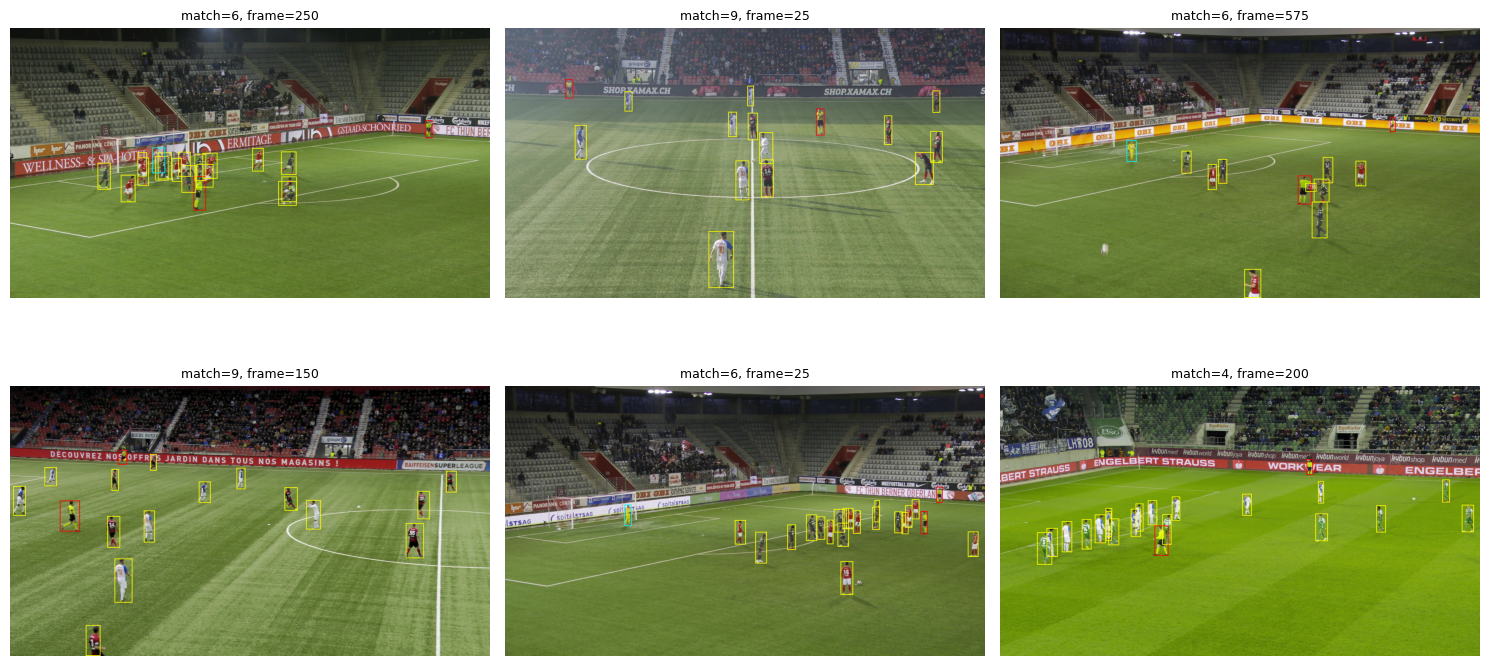

Bounding-box overview saved:  /kaggle/working/football_project_outputs/20261025T190854Z/bbox_alignment_review.png


In [9]:
fig,axes=plt.subplots(2,3,figsize=(15,8));rng=np.random.default_rng(SEED)
for ax,ix in zip(axes.flat,rng.choice(len(frames),size=min(6,len(frames)),replace=False)):
    record=frames.iloc[ix]
    with Image.open(record.path) as im: rgb=im.convert('RGB').copy()
    dr=ImageDraw.Draw(rgb)
    for b in boxes[boxes.frame_id==record.frame_id].itertuples():
        dr.rectangle((b.x1,b.y1,b.x2,b.y2),outline={'player':'yellow','goalkeeper':'cyan','referee':'red'}[b.role],width=3)
    ax.imshow(rgb);ax.set_title(f'match={record.match_id}, frame={record.ordinal}',fontsize=9);ax.axis('off')
for ax in axes.flat:
    if not ax.images: ax.axis('off')
plt.tight_layout();plt.savefig(OUT/'bbox_alignment_review.png',dpi=120);plt.show()
print('Bounding-box overview saved: ', OUT/'bbox_alignment_review.png')


### M1 — Match-level train, validation, and test split

Partition the data by match rather than by individual frame, preventing images from the same game from appearing in multiple splits. Summarize the retained annotations, label distribution, and match membership for each partition. With three matches, each split contains one match, so the frame proportions may differ from the target fractions.


In [10]:
# Automated M1 source/box audit (no user-edited CSV)
source_ok = clips['match_id_from_source'].fillna(False).astype(bool)
invalid_sources = set(clips.loc[~source_ok,'source'].astype(str))
if invalid_sources:
    print('Excluding sequences missing source-provided match identity:',len(invalid_sources))
    frames=frames[~frames.source_json.isin(invalid_sources)].copy()
valid_ids=set(frames.frame_id)
boxes=boxes[boxes.frame_id.isin(valid_ids)].copy()
geom=(boxes.x1>=0)&(boxes.y1>=0)&(boxes.x2>boxes.x1)&(boxes.y2>boxes.y1)
frame_dimensions=frames.set_index('frame_id')[['width','height']]
joined=boxes.join(frame_dimensions,on='frame_id',how='left')
geom &= (joined.x2<=joined.width)&(joined.y2<=joined.height)
dropped=int((~geom).sum());boxes=boxes.loc[geom].copy()
# Exclude images without retained people boxes, rather than inventing labels
kept=set(boxes.frame_id)
removed_empty=int((~frames.frame_id.isin(kept)).sum())
frames=frames[frames.frame_id.isin(kept)].copy()
pd.DataFrame([{'stage':'M1','rejected_invalid_boxes':dropped,'rejected_no_boxes_frames':removed_empty,
               'excluded_unknown_match_sources':len(invalid_sources)}]).to_csv(OUT/'automatic_m1_cleaning.csv',index=False)
print('Automatic cleaning: invalid boxes',dropped,'| empty frames removed',removed_empty)


Automatic cleaning: invalid boxes 0 | empty frames removed 0


In [11]:
# Strict group-by-match split. No manual review gates; preserve provenance warning.
match_values=np.array(sorted(frames.match_id.astype(str).unique()))
if len(match_values)<3:raise RuntimeError('Need at least 3 source-identified matches for train/val/test.')
if len(match_values)<CFG['min_independent_matches']:
    print('WARNING: Fewer groups than configured. Dataset needs more independent matches.')
# With three groups, one match goes to each partition; for more, group shuffle.
if len(match_values)==3:
    rng=np.random.default_rng(SEED); shuffled=rng.permutation(match_values)
    assigned={str(shuffled[0]):'train',str(shuffled[1]):'val',str(shuffled[2]):'test'}
else:
    outer=GroupShuffleSplit(n_splits=1,test_size=CFG['test_fraction'],random_state=SEED)
    i,j=next(outer.split(match_values,groups=match_values))
    trainval_matches=match_values[i]; test_matches=match_values[j]
    inner=GroupShuffleSplit(n_splits=1,test_size=CFG['val_fraction']/(1-CFG['test_fraction']),random_state=SEED+1)
    a,b=next(inner.split(trainval_matches,groups=trainval_matches))
    assigned={str(m):'train' for m in trainval_matches[a]}
    assigned.update({str(m):'val' for m in trainval_matches[b]})
    assigned.update({str(m):'test' for m in test_matches})
frames['match_id']=frames.match_id.astype(str)
frames['split']=frames.match_id.map(assigned)
boxes=boxes.drop(columns=['match_id','split','path'],errors='ignore').merge(
    frames[['frame_id','split','path','match_id']],on='frame_id',how='inner',validate='many_to_one')
assert frames.groupby('match_id').split.nunique().max()==1
assert set(frames.split)=={'train','val','test'}
frames.to_csv(OUT/'frame_manifest.csv',index=False);boxes.to_csv(OUT/'person_boxes.csv',index=False)
print('Automated match-level split (source-provided IDs):');display(pd.crosstab(frames.split,frames.match_id))
display(pd.crosstab(boxes.split,boxes.role))


Automated match-level split (source-provided IDs):


match_id,4,6,9
split,,,
test,540,0,0
train,0,0,330
val,0,570,0


role,goalkeeper,player,referee
split,,,
test,275,8539,817
train,199,4165,482
val,339,7802,768


### M1 — Role crops and class distribution

Extract person crops from valid boxes, filter small or repeated crops, and inspect the distribution of `player`, `goalkeeper`, and `referee` samples across the three splits.


In [12]:
records=[];seen={} ;invalid=[]
# Process minority roles too; deterministic order then limit each class globally to manageable subset.
for b in tqdm(boxes.itertuples(index=False),total=len(boxes),desc='Save role crops'):
    if min(b.x2-b.x1,b.y2-b.y1)<CFG['min_crop_side']:
        invalid.append({'frame_id':b.frame_id,'reason':'tiny role crop'});continue
    with Image.open(b.path) as im: crop=im.convert('RGB').crop((b.x1,b.y1,b.x2,b.y2))
    digest=hashlib.sha256(np.array(crop.resize((48,48))).tobytes()).hexdigest()
    if digest in seen:
        old_match,old_role=seen[digest]
        if old_match!=b.match_id:
            raise ValueError(f'Exact near-normalized duplicate crop across MATCHES: {old_match} vs {b.match_id}; review match grouping or duplicate provenance BEFORE splitting.')
        if old_role!=b.role:
            invalid.append({'frame_id':b.frame_id,'reason':'duplicate image with conflicting role'})
        continue
    seen[digest]=(b.match_id,b.role)
    ix=len(records)
    target=CACHE/'role_crops'/b.role/f'{safe_id(b.frame_id)}_{ix}.jpg'
    target.parent.mkdir(parents=True,exist_ok=True);crop.save(target,quality=94)
    records.append({'path':str(target),'role':b.role,'label':ROLE_TO_ID[b.role],
                    'split':b.split,'match_id':b.match_id,'frame_id':b.frame_id,'sha256':digest})
crops=pd.DataFrame(records)
# Sample TRAIN only, to keep an efficient project subset without discarding held-out evaluation.
rng=np.random.default_rng(SEED)
keep=[]
for (split,role),g in crops.groupby(['split','role']):
    cap=CFG['max_crop_per_class'] if split=='train' else max(200,CFG['max_crop_per_class']//4)
    keep.extend(g.sample(n=min(cap,len(g)),random_state=SEED).index.tolist())
crops=crops.loc[sorted(keep)].reset_index(drop=True)
crops.to_csv(OUT/'role_manifest.csv',index=False)
pd.DataFrame(invalid).to_csv(OUT/'invalid_role_crops.csv',index=False)
class_balance=pd.crosstab(crops.split,crops.role).reindex(index=['train','val','test'],columns=ROLE_NAMES,fill_value=0)
display(class_balance)
if (class_balance==0).any().any():
    raise ValueError('At least one split lacks one of the roles; add games or choose a documented role scheme. Do NOT mix match groups.')
print('Role crop count:',len(crops),'| filtered:',len(invalid))

Save role crops:   0%|          | 0/23386 [00:00<?, ?it/s]

role,player,goalkeeper,referee
split,,,
train,3500,194,444
val,875,323,653
test,875,230,658


Role crop count: 7752 | filtered: 1592


### M1 — Annotation quality checks

Summarize retained crops, role frequencies, match coverage, and repeated or invalid samples. These checks assess the consistency of the extracted annotations rather than independently verifying every role label.


In [13]:
# Automated crop label consistency checks; no human validation fields.
audit_report=crops.groupby(['split','role']).agg(count=('path','size'),unique_matches=('match_id','nunique')).reset_index()
audit_report.to_csv(OUT/'automatic_crop_audit.csv',index=False)
display(audit_report)
print('Semantic label-error upper bound: NOT MEASURABLE without an independently labeled audit.')


,split,role,count,unique_matches
0,test,goalkeeper,230,1
1,test,player,875,1
2,test,referee,658,1
3,train,goalkeeper,194,1
4,train,player,3500,1
5,train,referee,444,1
6,val,goalkeeper,323,1
7,val,player,875,1
8,val,referee,653,1


Semantic label-error upper bound: NOT MEASURABLE without an independently labeled audit.


### M1 — Dataset summary and limitations

Document the source dataset, frame-sampling and crop-extraction rules, match-level split, and class balance. Record limitations associated with occlusion, small objects, differences between matches, and annotation uncertainty.


In [14]:
card_path=REVIEW/'dataset_card.json'
if not card_path.exists():
    card=dict(title='Football SoccerNet GSR local project subset',sources=['SoccerNet/SN-GSR-2025',
        'SoccerNet/SN-Tracking-2023 (metadata review only; MOT class IDs absent)'],
        schema='GSR object bbox_image and role/team attributes; optional manually validated ball boxes/pitch masks',
        selected_clips=len(clips),matches=int(frames.match_id.nunique()),sampled_frames=len(frames),
        crops=len(crops),labels=ROLE_NAMES,split='GroupShuffleSplit by source info.game_id',
        sampling=f'Every {CFG["frame_step"]} source frames, max {CFG["max_frames_per_clip"]} per clip',
        license_verified=False,license_evidence='TODO: direct dataset card + media rights',
        anonymization_and_consent='TODO: review faces/identifiers and redistribution',
        match_group_verified=False,known_weaknesses='Domain shift, ball imbalance, occlusion, broadcast shots')
    card_path.write_text(json.dumps(card,indent=2))
print('Dataset card:',card_path)

Dataset card: /kaggle/working/football_project_outputs/20261025T190854Z/quality_checks/dataset_card.json


In [ ]:
# M1 — Dataset card and provenance review
# Document the dataset produced above without modifying the data or split.
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

card_file = REVIEW / "dataset_card.json"
original = json.loads(card_file.read_text(encoding="utf-8")) if card_file.exists() else {}
backup_file = REVIEW / "dataset_card_before_update.json"
if card_file.exists() and not backup_file.exists():
    backup_file.write_text(card_file.read_text(encoding="utf-8"), encoding="utf-8")

role_counts = pd.crosstab(crops["split"], crops["role"]).reindex(
    index=["train", "val", "test"], columns=ROLE_NAMES, fill_value=0
)
match_counts = frames.groupby("split")["match_id"].nunique().reindex(
    ["train", "val", "test"], fill_value=0
)
duplicate_crop_hashes = int(crops["sha256"].duplicated().sum())
match_overlap = int((frames.groupby("match_id")["split"].nunique() > 1).sum())

card = dict(original)
card.update({
    "dataset_name": "SoccerNet SN-GSR-2025 — sampled football player-role crops",
    "source_reference": "https://huggingface.co/datasets/SoccerNet/SN-GSR-2025",
    "source_annotations": (
        "Labels-GameState.json: image identifiers, bounding boxes (bbox_image), "
        "role and team attributes, plus available source match identifiers. "
        "Source image files or video frames provide the pixels."
    ),
    "task_and_labels": (
        "Three-class image classification: player (0), goalkeeper (1), "
        "referee (2). Other roles and objects are not included in the "
        "role-classification crop dataset."
    ),
    "processing": (
        f"Sample every {CFG['frame_step']} annotated source frames, with up to "
        f"{CFG['max_frames_per_clip']} sampled frames per clip and "
        f"{CFG['max_clips']} inspected clips. Decode available images or "
        "video frames, convert to RGB, validate and clip annotation boxes, "
        f"exclude crops smaller than {CFG['min_crop_side']} pixels on either "
        "side, and save role crops as JPEG images. Crop hashes use resized "
        "48x48 RGB pixels for repeat detection. Training and evaluation "
        "samples are capped per class according to the experiment configuration."
    ),
    "source_group_semantics": (
        "Split by match identifier taken from source annotations. "
        "Sequences without a source-provided match identifier are excluded "
        "before splitting; repeated crop hashes across different matches "
        "raise an error. Match identifiers and normalized crop hashes do not "
        "prove the absence of other visually related or near-duplicate content."
    ),
    "split_method": (
        "Match-group train/validation/test split using the configured seed "
        f"({CFG['seed']}); groups are not shared between splits. With exactly "
        "three matches, assign one match to each split. Otherwise use two "
        "GroupShuffleSplit stages. Splits are not guaranteed to be "
        "stratified by role."
    ),
    "dataset_counts": (
        f"Retained {len(clips)} inspected sequences, {frames.match_id.nunique()} "
        f"source-identified matches, {len(frames)} sampled retained frames, "
        f"{len(boxes)} person annotations, and {len(crops)} role crops. "
        f"Retained crop hash duplicates: {duplicate_crop_hashes}. "
        f"Match IDs appearing in multiple splits: {match_overlap}."
    ),
    "class_distribution": role_counts.to_dict(orient="index"),
    "matches_per_split": {str(k): int(v) for k, v in match_counts.items()},
    "label_review": (
        "Role labels are mapped automatically from source annotation attributes. "
        "Bounding-box geometry, split grouping, duplicate crop hashes, and "
        "per-role counts are checked programmatically. These checks do not "
        "constitute an independently labeled manual audit; semantic label "
        "accuracy has not been independently measured."
    ),
    "license_and_verification": (
        "Dataset-level license and individual media reuse rights have not "
        "been independently verified in this notebook. Confirm the current "
        "SoccerNet dataset terms, attribution requirements, and image/video "
        "rights before redistribution or use beyond the academic experiment."
    ),
    "privacy_and_consent": (
        "Football footage may depict identifiable people. This notebook "
        "does not establish individual consent or image ownership. Restrict "
        "access as appropriate; do not infer identities or redistribute "
        "identifiable frames without reviewing applicable rights and privacy obligations."
    ),
    "intended_use": (
        "Academic development and evaluation of three-class football "
        "player-role classification from annotated match footage."
    ),
    "limitations": (
        "Selected and capped sample rather than the complete source dataset; "
        "role imbalance, small and occluded people, kit similarity, camera "
        "angles, and match/domain shift can affect performance. Automated "
        "role labels may contain annotation errors. Unique match IDs and "
        "crop hashes do not demonstrate complete source independence. "
        "Results are not validated for operational deployment."
    ),
})
card_file.write_text(json.dumps(card, indent=2, ensure_ascii=False), encoding="utf-8")

# Produce a readable dataset card and a transparent documentation status.
lines = ["# Dataset card"]
for key, value in card.items():
    title = key.replace("_", " ").title()
    rendered = json.dumps(value, indent=2, ensure_ascii=False) if isinstance(value, (dict, list)) else str(value)
    lines.append(f"## {title}\n{rendered}")
(OUT / "dataset_card.md").write_text("\n\n".join(lines) + "\n", encoding="utf-8")

status = pd.DataFrame([
    ("Source annotations and role mapping", "Documented from extraction code"),
    ("Match-level split separation", "Pass" if match_overlap == 0 else "Review required"),
    ("Retained crop hash uniqueness", "Pass" if duplicate_crop_hashes == 0 else "Review required"),
    ("Crop counts and class distribution", "Recorded"),
    ("Independent semantic label audit", "Not performed"),
    ("Dataset licensing and individual media rights", "Not independently verified"),
    ("Privacy and consent", "Not independently verified"),
], columns=["Check", "Status"])
status.to_csv(OUT / "dataset_card_review_status.csv", index=False)
role_counts.to_csv(OUT / "dataset_card_class_balance.csv")

display(pd.DataFrame([(k, str(v)) for k, v in card.items()], columns=["Field", "Content"])
        .style.set_properties(**{"text-align": "left", "white-space": "normal"})
        .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}]))
print("Class distribution by split:")
display(role_counts)
print("Documentation and verification status:")
display(status)
print("Dataset card saved:", OUT / "dataset_card.md")


## M2–M3 — Classification preprocessing

Resize player-role crops to 224 × 224 and apply ImageNet normalization. Use horizontal flips and colour jitter for training, deterministic transformations for evaluation, and class-weighted cross-entropy to address class imbalance.


In [15]:
IMAGENET_MEAN=[.485,.456,.406];IMAGENET_STD=[.229,.224,.225]
train_tf=transforms.Compose([transforms.Resize((CFG['image_size'],CFG['image_size'])),
    transforms.RandomHorizontalFlip(),transforms.ColorJitter(.15,.15,.15,.04),
    transforms.ToTensor(),transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD)])
eval_tf=transforms.Compose([transforms.Resize((CFG['image_size'],CFG['image_size'])),
    transforms.ToTensor(),transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD)])
class RoleDS(Dataset):
    def __init__(self,frame,training=False):self.frame=frame.reset_index(drop=True);self.tf=train_tf if training else eval_tf
    def __len__(self):return len(self.frame)
    def __getitem__(self,index):
        r=self.frame.iloc[index]
        with Image.open(r.path) as im: x=self.tf(im.convert('RGB'))
        return x,int(r.label)

def make_loader(split,train=False,subset=None):
    table=crops[crops.split==split] if subset is None else subset
    return DataLoader(RoleDS(table,train),batch_size=CFG['batch_size'],shuffle=train,
                      num_workers=CFG['num_workers'],pin_memory=(DEVICE.type=='cuda'))
train_loader=make_loader('train',True);val_loader=make_loader('val')
counts=crops[crops.split=='train'].label.value_counts().reindex(range(len(ROLE_NAMES)),fill_value=0)
class_weights=torch.tensor((counts.sum()/(len(ROLE_NAMES)*counts)).to_numpy(),dtype=torch.float32).to(DEVICE)
print('Train weights:',dict(zip(ROLE_NAMES,class_weights.cpu().tolist())))

Train weights: {'player': 0.394095242023468, 'goalkeeper': 7.109965801239014, 'referee': 3.1066067218780518}


## M3 — Pretrained backbone comparison

Compare feature representations from ResNet-18, ResNet-34, MobileNetV3-Small, EfficientNet-B0, and ConvNeXt-Tiny on balanced role samples. Use this screening stage to inform backbone selection for the classification experiments.


In [16]:
MODEL_CANDIDATES=['resnet18','resnet34','mobilenet_v3_small','efficientnet_b0','convnext_tiny']
WEIGHT_TYPES={'resnet18':models.ResNet18_Weights.DEFAULT,'resnet34':models.ResNet34_Weights.DEFAULT,
    'mobilenet_v3_small':models.MobileNet_V3_Small_Weights.DEFAULT,
    'efficientnet_b0':models.EfficientNet_B0_Weights.DEFAULT,'convnext_tiny':models.ConvNeXt_Tiny_Weights.DEFAULT}

def make_backbone(name,pretrained=True,extractor=False):
    model=getattr(models,name)(weights=WEIGHT_TYPES[name] if pretrained else None)
    if name.startswith('resnet'):
        input_dim=model.fc.in_features;model.fc=nn.Identity() if extractor else nn.Linear(input_dim,len(ROLE_NAMES))
    else:
        input_dim=model.classifier[-1].in_features
        model.classifier[-1]=nn.Identity() if extractor else nn.Linear(input_dim,len(ROLE_NAMES))
    return model

def sample_per_role(split,n):
    return pd.concat([g.sample(min(n,len(g)),random_state=SEED)
                      for _,g in crops[crops.split==split].groupby('role')]).reset_index(drop=True)
proto_train=sample_per_role('train',CFG['prototype_train_per_class'])
proto_val=sample_per_role('val',CFG['prototype_val_per_class'])

def extract_features(model,table):
    loader=DataLoader(RoleDS(table,False),batch_size=CFG['batch_size'],num_workers=CFG['num_workers'])
    feats=[];labs=[];model.eval()
    with torch.inference_mode():
        for x,y in loader:
            z=model(x.to(DEVICE));z=torch.flatten(z,1)
            feats.append(F.normalize(z,dim=1).cpu());labs.append(y)
    return torch.cat(feats),torch.cat(labs)

baseline_file=OUT/'five_pretrained_prototypes.csv'
if baseline_file.exists():baseline_results=pd.read_csv(baseline_file).to_dict('records')
else:baseline_results=[]
finished={r['model'] for r in baseline_results}
for name in MODEL_CANDIDATES:
    if name in finished:continue
    backbone=make_backbone(name,pretrained=True,extractor=True).to(DEVICE)
    ft,yt=extract_features(backbone,proto_train);fv,yv=extract_features(backbone,proto_val)
    prototypes=torch.stack([F.normalize(ft[yt==k].mean(0),dim=0) for k in range(len(ROLE_NAMES))])
    prediction=(fv@prototypes.T).argmax(1)
    result={'model':name,'validation_macro_f1':float(f1_score(yv,prediction,average='macro',zero_division=0)),
            'validation_accuracy':float(accuracy_score(yv,prediction)),
            'n_validation':len(yv),'kind':'frozen_embedding_class_prototype'}
    baseline_results.append(result)
    pd.DataFrame(baseline_results).to_csv(baseline_file,index=False)
    print(name,result)
    del backbone,ft,fv,prototypes;gc.collect()
    if DEVICE.type=='cuda':torch.cuda.empty_cache()
    if DEVICE.type=='mps':torch.mps.empty_cache()
baselines=pd.DataFrame(baseline_results).sort_values(['validation_macro_f1','validation_accuracy'],ascending=False)
BACKBONE=str(baselines.iloc[0].model)
(OUT/'selected_backbone.json').write_text(json.dumps({'backbone':BACKBONE,'selection_set':'validation',
    'selection_metric':'prototype macro-F1','not_a_trained_classifier':True},indent=2))
display(baselines);print('Backbone selected from validation only:',BACKBONE)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 179MB/s]


resnet18 {'model': 'resnet18', 'validation_macro_f1': 0.712867706004961, 'validation_accuracy': 0.7222222222222222, 'n_validation': 270, 'kind': 'frozen_embedding_class_prototype'}
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 203MB/s]


resnet34 {'model': 'resnet34', 'validation_macro_f1': 0.7422457785040567, 'validation_accuracy': 0.7481481481481481, 'n_validation': 270, 'kind': 'frozen_embedding_class_prototype'}
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


...

efficientnet_b0 {'model': 'efficientnet_b0', 'validation_macro_f1': 0.6960381412839108, 'validation_accuracy': 0.7074074074074074, 'n_validation': 270, 'kind': 'frozen_embedding_class_prototype'}
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 142MB/s] 


convnext_tiny {'model': 'convnext_tiny', 'validation_macro_f1': 0.7530525846702317, 'validation_accuracy': 0.7518518518518519, 'n_validation': 270, 'kind': 'frozen_embedding_class_prototype'}


,model,validation_macro_f1,validation_accuracy,n_validation,kind
4,convnext_tiny,0.753053,0.751852,270,frozen_embedding_class_prototype
1,resnet34,0.742246,0.748148,270,frozen_embedding_class_prototype
0,resnet18,0.712868,0.722222,270,frozen_embedding_class_prototype
2,mobilenet_v3_small,0.710985,0.714815,270,frozen_embedding_class_prototype
3,efficientnet_b0,0.696038,0.707407,270,frozen_embedding_class_prototype


Backbone selected from validation only: convnext_tiny


## M2–M3 — Classifier architectures

Define three training approaches for the same three-class task: a CNN trained from scratch, a pretrained backbone with frozen features and a trainable classification head, and a pretrained network fine-tuned end to end.


In [17]:
class ScratchCNN(nn.Module):
    def __init__(self,n_classes=len(ROLE_NAMES)):
        super().__init__();blocks=[];channels=3
        for width in (32,64,128,256):
            blocks.extend([nn.Conv2d(channels,width,3,padding=1),nn.BatchNorm2d(width),nn.ReLU(),nn.MaxPool2d(2)])
            channels=width
        self.features=nn.Sequential(*blocks)
        self.head=nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Dropout(.25),nn.Linear(channels,n_classes))
    def forward(self,x):return self.head(self.features(x))

def build_role_model(mode):
    if mode=='scratch':return ScratchCNN()
    model=make_backbone(BACKBONE,pretrained=True,extractor=False)
    if mode=='frozen':
        for p in model.parameters():p.requires_grad=False
        head=model.fc if BACKBONE.startswith('resnet') else model.classifier[-1]
        for p in head.parameters():p.requires_grad=True
    return model

def role_logits(model,x):return model(x)

### M2–M3 — Training and model selection

Train with AdamW, weight decay, learning-rate scheduling, gradient clipping, and early stopping. Use a learning rate of `1e-3` for the scratch and frozen-backbone models and `1e-4` for full fine-tuning. Record epoch-level losses and classification metrics, and save the checkpoint with the lowest validation loss.


In [18]:
def evaluate_loader(model,loader,loss_fn):
    model.eval();n=0;loss_total=0;probs=[];ys=[]
    with torch.inference_mode():
        for x,y in loader:
            x=x.to(DEVICE);y=y.to(DEVICE);logits=role_logits(model,x)
            loss_total+=loss_fn(logits,y).item()*len(y);n+=len(y)
            probs.append(logits.softmax(1).cpu().numpy());ys.extend(y.cpu().tolist())
    probabilities=np.concatenate(probs)
    predicted=probabilities.argmax(1)
    return {'loss':loss_total/n,'accuracy':accuracy_score(ys,predicted),
            'macro_f1':f1_score(ys,predicted,average='macro',zero_division=0)},np.array(ys),probabilities

def train_mode(mode):
    seed=CFG['seed'];random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    model=build_role_model(mode).to(DEVICE)
    criterion=nn.CrossEntropyLoss(weight=class_weights)
    lr=CFG['scratch_lr'] if mode=='scratch' else CFG['frozen_lr'] if mode=='frozen' else CFG['full_lr']
    epochs=CFG[f'{mode}_epochs']
    optim=torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],lr=lr,
                            weight_decay=CFG['weight_decay'])
    sched=torch.optim.lr_scheduler.ReduceLROnPlateau(optim,mode='min',factor=.5,patience=2)
    d=OUT/'classification'/mode;d.mkdir(parents=True,exist_ok=True)
    best_loss=float('inf');stale=0;history=[]
    run=wandb.init(project=CFG['wandb_project'],name='role_'+mode+'_'+RUN_ID,
        group=RUN_ID,mode=CFG['wandb_mode'],dir=str(OUT),config={**CFG,'mode':mode,'backbone':BACKBONE},reinit=True)
    try:
        for epoch in range(epochs):
            model.train();train_loss=0;seen=0
            for x,y in tqdm(train_loader,desc=f'{mode} epoch {epoch+1}/{epochs}',leave=False):
                x=x.to(DEVICE);y=y.to(DEVICE)
                optim.zero_grad(set_to_none=True)
                if mode=='frozen':
                    # Frozen BatchNorm running statistics must not adapt during head-only training.
                    model.eval()
                    head=model.fc if BACKBONE.startswith('resnet') else model.classifier[-1]
                    head.train()
                logits=role_logits(model,x)
                loss=criterion(logits,y);loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(),CFG['grad_clip'])
                optim.step();train_loss+=loss.item()*len(y);seen+=len(y)
            vm,_,_=evaluate_loader(model,val_loader,criterion)
            sched.step(vm['loss'])
            h={'epoch':epoch+1,'train_loss':train_loss/max(1,seen),
               'val_loss':vm['loss'],'val_accuracy':vm['accuracy'],
               'val_macro_f1':vm['macro_f1'],'lr':optim.param_groups[0]['lr']}
            history.append(h);run.log(h);print(mode,h)
            if vm['loss']<best_loss-1e-4:
                best_loss=vm['loss'];stale=0
                torch.save({'state_dict':model.state_dict(),'mode':mode,'backbone':BACKBONE,
                            'labels':ROLE_NAMES,'config':CFG},d/'best.pt')
            else:
                stale+=1
                if stale>=CFG['patience']:
                    print('Early stop after',epoch+1,'epochs');break
        pd.DataFrame(history).to_csv(d/'history.csv',index=False)
        run.summary['best_val_loss']=best_loss
    finally:
        run.finish();del model;gc.collect()
        if DEVICE.type=='cuda':torch.cuda.empty_cache()
        if DEVICE.type=='mps':torch.mps.empty_cache()
    return {'mode':mode,'best_val_loss':best_loss,'checkpoint':str(d/'best.pt')}

### M2–M3 — Classifier training

Run the scratch CNN, frozen-backbone classifier, and fully fine-tuned classifier separately. Save each experiment's checkpoint and training history for evaluation.


In [19]:
scratch_result=train_mode('scratch')

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


scratch epoch 1/16:   0%|          | 0/130 [00:00<?, ?it/s]

scratch {'epoch': 1, 'train_loss': 0.48455073117287967, 'val_loss': 1.0291678016730608, 'val_accuracy': 0.7585089141004863, 'val_macro_f1': 0.6899897595897698, 'lr': 0.001}


scratch epoch 2/16:   0%|          | 0/130 [00:00<?, ?it/s]

scratch {'epoch': 2, 'train_loss': 0.3719965199835926, 'val_loss': 0.9298005904750782, 'val_accuracy': 0.5856293895191789, 'val_macro_f1': 0.5649737738987232, 'lr': 0.001}


...

scratch epoch 11/16:   0%|          | 0/130 [00:00<?, ?it/s]

scratch {'epoch': 11, 'train_loss': 0.10081251953454366, 'val_loss': 1.1810351649227817, 'val_accuracy': 0.6747703943814155, 'val_macro_f1': 0.6398662625875114, 'lr': 0.00025}


scratch epoch 12/16:   0%|          | 0/130 [00:00<?, ?it/s]

scratch {'epoch': 12, 'train_loss': 0.08723128527860212, 'val_loss': 1.064376472943799, 'val_accuracy': 0.6963803349540789, 'val_macro_f1': 0.6536966380345095, 'lr': 0.00025}
Early stop after 12 epochs


epoch,▁▂▂▃▄▄▅▅▆▇▇█
lr,████▃▃▃▃▃▃▁▁
train_loss,█▆▄▄▂▂▁▂▁▁▁▁
val_accuracy,▇▁▄▄▇▅▆▆▃█▄▅
val_loss,▃▂█▄▃▂▄▁▃▃▄▃
val_macro_f1,▇▁▄▃█▆▆▆▂█▄▅
best_val_loss,0.76668
epoch,12
lr,0.00025
train_loss,0.08723
val_accuracy,0.69638


In [20]:
frozen_result=train_mode('frozen')

frozen epoch 1/10:   0%|          | 0/130 [00:00<?, ?it/s]

frozen {'epoch': 1, 'train_loss': 0.2974472721240093, 'val_loss': 0.45363663089462125, 'val_accuracy': 0.8649378714208535, 'val_macro_f1': 0.8318813709518534, 'lr': 0.001}


frozen epoch 2/10:   0%|          | 0/130 [00:00<?, ?it/s]

frozen {'epoch': 2, 'train_loss': 0.0721807982705069, 'val_loss': 0.5888414250909155, 'val_accuracy': 0.8573743922204214, 'val_macro_f1': 0.8000906058150922, 'lr': 0.001}


frozen epoch 3/10:   0%|          | 0/130 [00:00<?, ?it/s]

...

frozen epoch 6/10:   0%|          | 0/130 [00:00<?, ?it/s]

frozen {'epoch': 6, 'train_loss': 0.03505897010082839, 'val_loss': 0.4027594662498359, 'val_accuracy': 0.8806050783360346, 'val_macro_f1': 0.8564686382957745, 'lr': 0.0005}


frozen epoch 7/10:   0%|          | 0/130 [00:00<?, ?it/s]

frozen {'epoch': 7, 'train_loss': 0.025336495391329514, 'val_loss': 0.40295362583628735, 'val_accuracy': 0.882766072393301, 'val_macro_f1': 0.8592657372787246, 'lr': 0.0005}
Early stop after 7 epochs


epoch,▁▂▃▅▆▇█
lr,█████▁▁
train_loss,█▂▂▁▁▁▁
val_accuracy,▃▁█▅▆▆▆
val_loss,▄█▁▅▃▃▃
val_macro_f1,▄▁█▅▇▇▇
best_val_loss,0.34143
epoch,7
lr,0.0005
train_loss,0.02534
val_accuracy,0.88277


In [21]:
full_result=train_mode('full')

full epoch 1/10:   0%|          | 0/130 [00:00<?, ?it/s]

full {'epoch': 1, 'train_loss': 0.1504761915585974, 'val_loss': 0.6743219488454849, 'val_accuracy': 0.8708806050783361, 'val_macro_f1': 0.8301665032330184, 'lr': 0.0001}


full epoch 2/10:   0%|          | 0/130 [00:00<?, ?it/s]

full {'epoch': 2, 'train_loss': 0.02253268182597287, 'val_loss': 2.3338484313842893, 'val_accuracy': 0.8449486763911399, 'val_macro_f1': 0.6893603152268116, 'lr': 0.0001}


full epoch 3/10:   0%|          | 0/130 [00:00<?, ?it/s]

...

full epoch 6/10:   0%|          | 0/130 [00:00<?, ?it/s]

full {'epoch': 6, 'train_loss': 0.009693872983408507, 'val_loss': 1.8802749952718993, 'val_accuracy': 0.842247433819557, 'val_macro_f1': 0.755212436075576, 'lr': 5e-05}


full epoch 7/10:   0%|          | 0/130 [00:00<?, ?it/s]

full {'epoch': 7, 'train_loss': 0.0004163850078892429, 'val_loss': 2.0707036340132463, 'val_accuracy': 0.8665586169638033, 'val_macro_f1': 0.7941010099652677, 'lr': 5e-05}
Early stop after 7 epochs


epoch,▁▂▃▅▆▇█
lr,█████▁▁
train_loss,█▂▂▂▁▁▁
val_accuracy,▄▁▂▅█▁▄
val_loss,▃█▁▇▅▇▇
val_macro_f1,▇▁▇▅█▄▅
best_val_loss,0.21154
epoch,7
lr,5e-05
train_loss,0.00042
val_accuracy,0.86656


### M2–M3 — Validation comparison

Compare the trained models using validation loss and learning curves. Select a checkpoint using validation results before evaluating on the held-out test match.


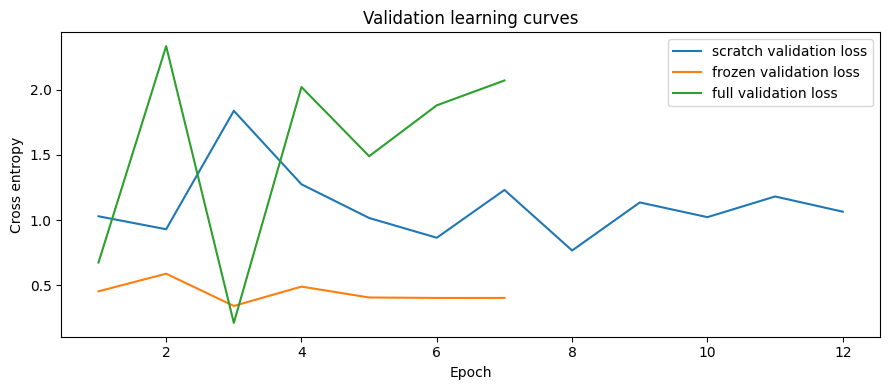

,mode,best_val_loss,checkpoint
2,full,0.211543,/kaggle/working/football_project_outputs/20261...
1,frozen,0.341430,/kaggle/working/football_project_outputs/20261...
0,scratch,0.766679,/kaggle/working/football_project_outputs/20261...


In [22]:
selection=pd.DataFrame([scratch_result,frozen_result,full_result]).sort_values('best_val_loss')
SELECTED_MODE=str(selection.iloc[0]['mode']);SELECTED_CKPT=str(selection.iloc[0]['checkpoint'])
selection.to_csv(OUT/'validation_model_selection.csv',index=False)
(OUT/'selected_role_model.json').write_text(json.dumps({'selected_mode':SELECTED_MODE,
    'checkpoint':SELECTED_CKPT,'selection_data':'validation only'},indent=2))
fig,ax=plt.subplots(figsize=(9,4))
for mode in ['scratch','frozen','full']:
    h=pd.read_csv(OUT/'classification'/mode/'history.csv')
    ax.plot(h.epoch,h.val_loss,label=f'{mode} validation loss')
ax.set(xlabel='Epoch',ylabel='Cross entropy',title='Validation learning curves');ax.legend();plt.tight_layout()
plt.savefig(OUT/'learning_curves.png',dpi=160);plt.show();display(selection)

### M2–M3 — Test-set evaluation

Evaluate the trained role classifiers on the held-out match. Report classification accuracy, Macro-F1, per-class precision and recall, confusion matrices, calibration error, and uncertainty estimates where available. Results from a single test match may not represent performance across all games.


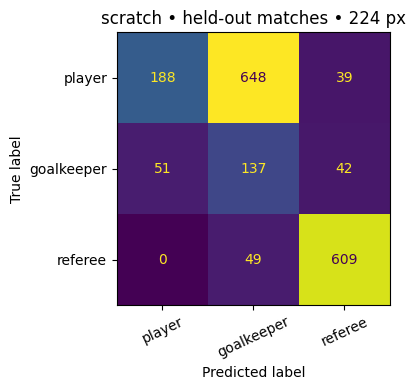

,role,precision,recall,F1,support
0,player,0.786611,0.214857,0.337522,875
1,goalkeeper,0.164269,0.595652,0.257519,230
2,referee,0.882609,0.925532,0.903561,658


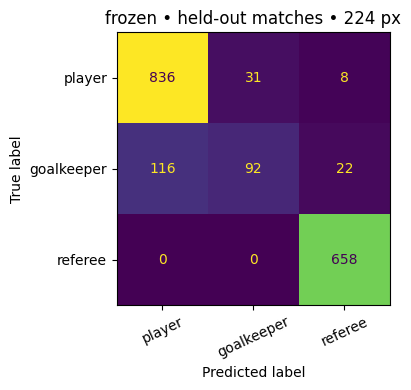

,role,precision,recall,F1,support
0,player,0.878151,0.955429,0.915161,875
1,goalkeeper,0.747967,0.400000,0.521246,230
2,referee,0.956395,1.000000,0.977712,658


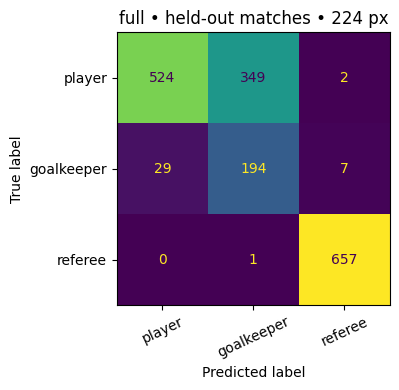

,role,precision,recall,F1,support
0,player,0.947559,0.598857,0.733894,875
1,goalkeeper,0.356618,0.843478,0.501292,230
2,referee,0.986486,0.998480,0.992447,658


,mode,split,n,matches,resolution,threshold,accuracy,macro_f1,ece,accuracy_ci95_low,accuracy_ci95_high
1,frozen,test / held-out matches,1763,1,224,argmax softmax,0.899603,0.804707,0.022333,None,None
2,full,test / held-out matches,1763,1,224,argmax softmax,0.779921,0.742544,0.189315,None,None
0,scratch,test / held-out matches,1763,1,224,argmax softmax,0.529779,0.499534,0.384004,None,None


In [23]:
def expected_calibration_error(y,p,bins=10):
    pred=p.argmax(1);conf=p.max(1);edges=np.linspace(0,1,bins+1);table=[]
    for b in range(bins):
        keep=(conf>=edges[b])&(conf<=edges[b+1] if b==bins-1 else conf<edges[b+1])
        if keep.sum():table.append({'bin':b,'n':int(keep.sum()),'mean_conf':float(conf[keep].mean()),
                                   'accuracy':float((pred[keep]==y[keep]).mean())})
    bins_df=pd.DataFrame(table)
    return float((bins_df.n/len(y)*(bins_df.accuracy-bins_df.mean_conf).abs()).sum()),bins_df

def match_bootstrap_accuracy(y,p,match_ids,B=2000):
    df=pd.DataFrame({'match_id':match_ids,'correct':(p.argmax(1)==y).astype(float)})
    agg=df.groupby('match_id').correct.agg(['sum','count'])
    if len(agg)<2:return [None,None]
    rr=np.random.default_rng(SEED);values=[];tot=agg.to_numpy()
    for _ in range(B):
        ix=rr.integers(0,len(tot),size=len(tot));values.append(tot[ix,0].sum()/tot[ix,1].sum())
    return np.quantile(values,[.025,.975]).tolist()

test_frame=crops[crops.split=='test'].reset_index(drop=True)
results=[]
for mode in ['scratch','frozen','full']:
    model=build_role_model(mode)
    ckpt=torch.load(OUT/'classification'/mode/'best.pt',map_location='cpu',weights_only=False)
    model.load_state_dict(ckpt['state_dict']);model.to(DEVICE).eval()
    stat,y,p=evaluate_loader(model,make_loader('test'),nn.CrossEntropyLoss())
    pred=p.argmax(1)
    precision,recall,f1,support=precision_recall_fscore_support(y,pred,labels=range(3),zero_division=0)
    ece,cal=expected_calibration_error(y,p)
    interval=match_bootstrap_accuracy(y,p,test_frame.match_id.values)
    d=OUT/'classification'/mode
    by_class=pd.DataFrame({'role':ROLE_NAMES,'precision':precision,'recall':recall,'F1':f1,'support':support})
    by_class.to_csv(d/'test_per_class.csv',index=False);cal.to_csv(d/'test_reliability.csv',index=False)
    summary={'mode':mode,'split':'test / held-out matches','n':len(y), 'matches':test_frame.match_id.nunique(),
             'resolution':CFG['image_size'],'threshold':'argmax softmax','accuracy':float(stat['accuracy']),
             'macro_f1':float(stat['macro_f1']),'ece':float(ece),
             'accuracy_ci95_low':interval[0],'accuracy_ci95_high':interval[1]}
    results.append(summary)
    preds=test_frame.copy()
    preds['prediction']=pred;preds['confidence']=p.max(1)
    preds.to_csv(d/'test_predictions.csv',index=False)
    fig,ax=plt.subplots(figsize=(5,4))
    ConfusionMatrixDisplay(confusion_matrix(y,pred,labels=range(3)),display_labels=ROLE_NAMES).plot(ax=ax,colorbar=False)
    plt.title(f'{mode} • held-out matches • {CFG["image_size"]} px');plt.xticks(rotation=25)
    plt.tight_layout();plt.savefig(d/'confusion_matrix.png',dpi=160);plt.show()
    display(by_class)
    del model;gc.collect()
final_comparison=pd.DataFrame(results).sort_values('macro_f1',ascending=False)
final_comparison.to_csv(OUT/'test_classifier_comparison.csv',index=False)
display(final_comparison)

### M2–M3 — Classification errors

Review incorrectly classified crops for each role. Examine whether kit similarities, occlusion, camera perspective, or goalkeeper appearance are associated with the observed errors.


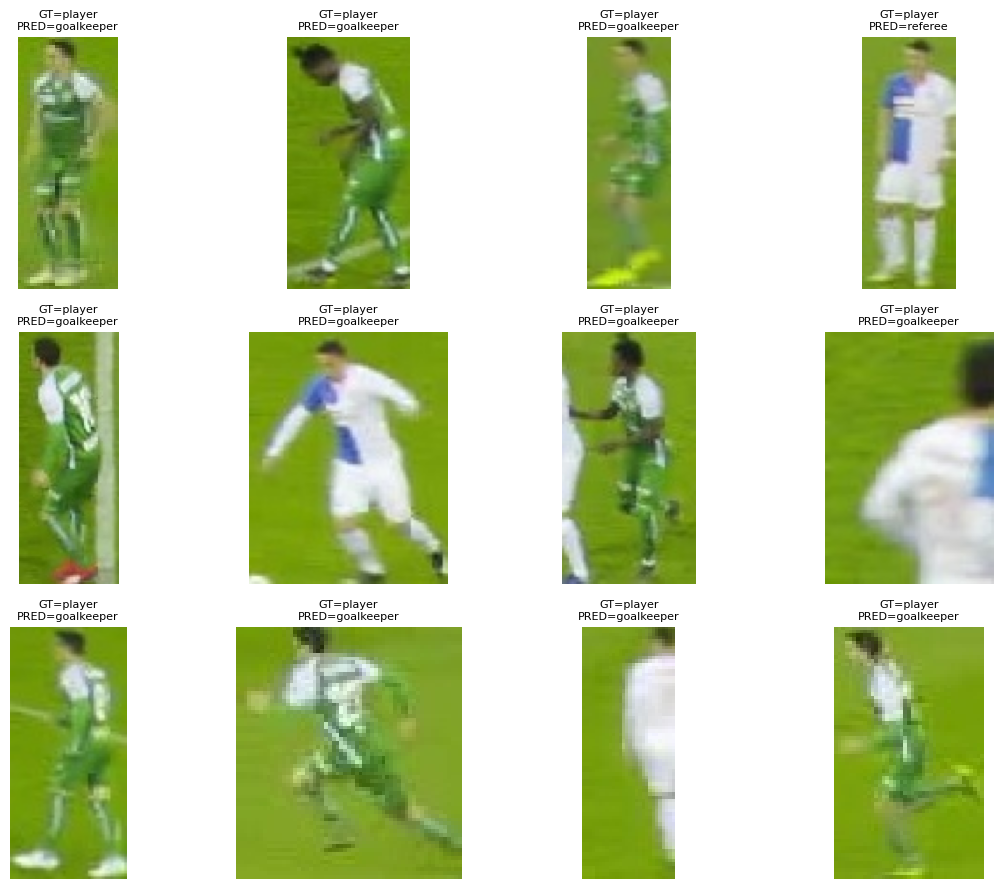

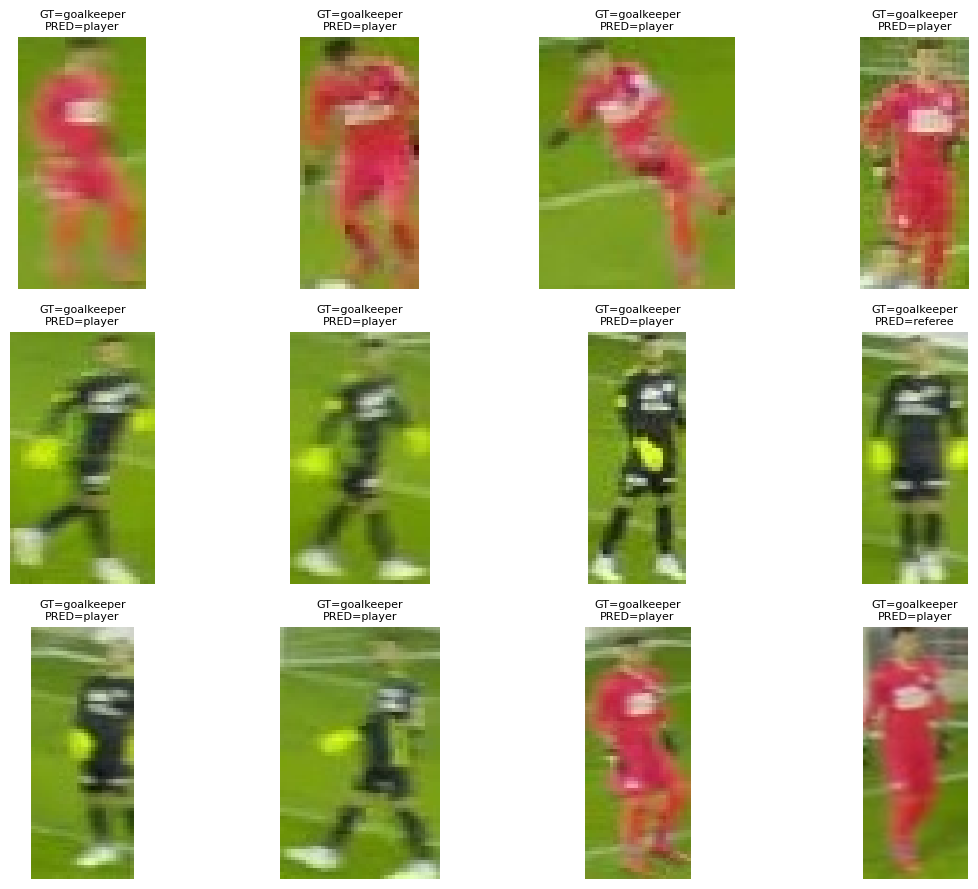

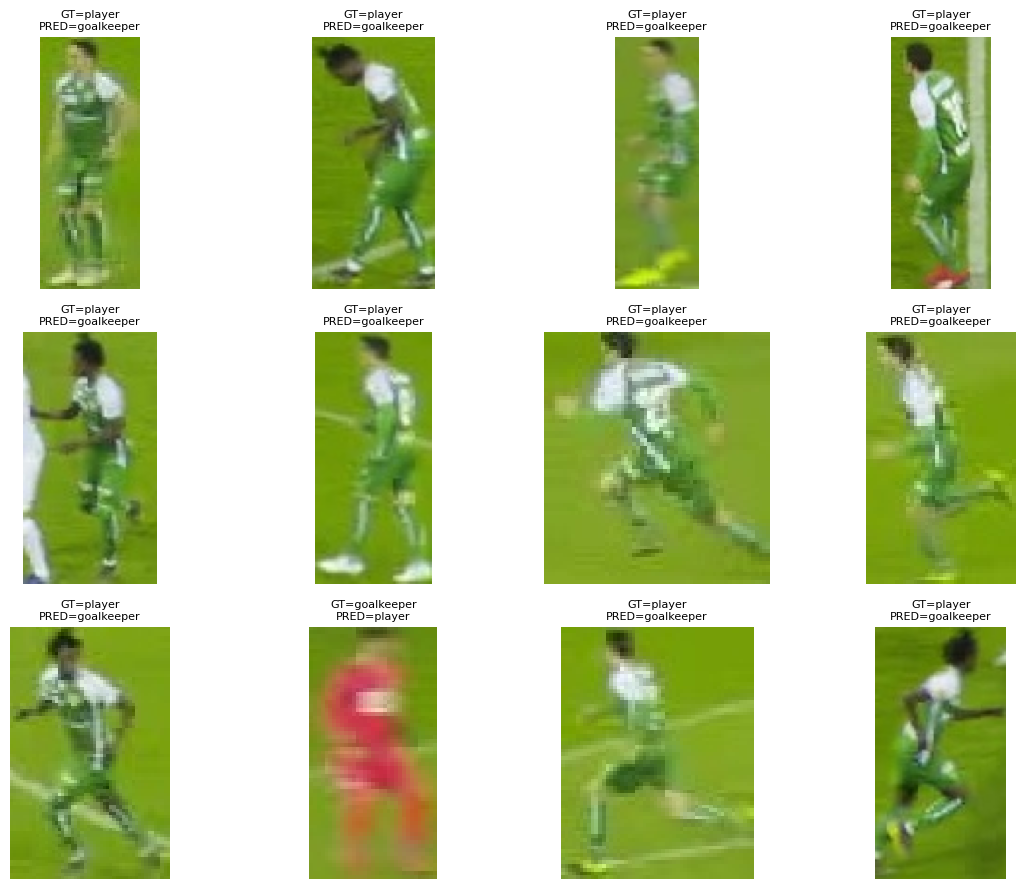

Review role errors and complete: /kaggle/working/football_project_outputs/20261025T190854Z/data_improvement_plan.md


In [24]:
for mode in ['scratch','frozen','full']:
    d=OUT/'classification'/mode
    wrong=pd.read_csv(d/'test_predictions.csv')
    wrong=wrong[wrong.prediction!=wrong.label].copy()
    wrong['failure_cause']='';wrong['evidence']='';wrong['suggested_fix']=''
    wrong.to_csv(d/'errors_for_review.csv',index=False)
    chosen=wrong.head(12)
    if len(chosen):
        fig,axes=plt.subplots(math.ceil(len(chosen)/4),4,figsize=(12,3*math.ceil(len(chosen)/4)),squeeze=False)
        for ax in axes.flat:ax.axis('off')
        for ax,r in zip(axes.flat,chosen.itertuples()):
            with Image.open(r.path) as im:ax.imshow(im)
            ax.set_title(f'GT={ROLE_NAMES[r.label]}\nPRED={ROLE_NAMES[r.prediction]}',fontsize=8)
        plt.tight_layout();plt.savefig(d/'failure_gallery.png',dpi=150);plt.show()
plan=OUT/'data_improvement_plan.md'
if not plan.exists():plan.write_text("""# Data improvement plan\n\n- Observed errors with frame IDs: TODO\n- Evidence for root cause (blur, camera angle, occlusion, class imbalance): TODO\n- Data/augmentation action: TODO\n- Validation-only experiment and acceptance criterion: TODO\n- Remaining licensing/domain-shift limitations: TODO\n""")
print('Review role errors and complete:',plan)

### Team appearance analysis

Examine visual differences between team kits using appearance features extracted from player crops. Compare appearance-based clusters with available team assignments, keeping team separation distinct from player-role classification.


In [25]:
def jersey_feature(b):
    with Image.open(b.path) as im:
        x1,y1,x2,y2=map(int,[b.x1,b.y1,b.x2,b.y2]); rgb=np.array(im.convert('RGB'))[y1:y2,x1:x2]
    if rgb.shape[0]<15 or rgb.shape[1]<12:return None
    hh,ww=rgb.shape[:2]
    chest=rgb[int(hh*.18):int(hh*.52),int(ww*.25):int(ww*.75)]
    hsv=cv2.cvtColor(chest,cv2.COLOR_RGB2HSV)
    return np.median(hsv.reshape(-1,3),axis=0)/np.array([180.,255.,255.])
team_scores=[]
for match_id, group in boxes[(boxes.split=='test')&(boxes.role=='player')].groupby('match_id'):
    samples=[];true=[]
    for r in group.itertuples():
        if r.team not in ['left','right']:continue
        f=jersey_feature(r)
        if f is None:continue
        samples.append(f);true.append(0 if r.team=='left' else 1)
    if len(samples)<20 or len(set(true))<2:continue
    clusters=KMeans(n_clusters=2,random_state=SEED,n_init=10).fit_predict(np.array(samples))
    # Only a permutation-invariant EVALUATION score, NOT deployment label alignment.
    label_acc=max(np.mean(clusters==true),np.mean(1-clusters==true))
    team_scores.append({'match_id':match_id,'players':len(true),'permutation_invariant_accuracy':label_acc})
team_df=pd.DataFrame(team_scores)
team_df.to_csv(OUT/'team_colour_clustering_test.csv',index=False)
print('Team clustering: no eligible held-out matches' if team_df.empty else '')
if not team_df.empty:display(team_df)

,match_id,players,permutation_invariant_accuracy
0,4,8516,0.520902


# Phase 1 — Classification performance and refinement

The following experiments compare classifier performance, test additional regularization, and examine an adjustment to goalkeeper predictions.


## Classification results and learning curves

Summarize training, validation, and test performance for the scratch, frozen-backbone, and fine-tuned classifiers. Display classification metrics, learning curves, and the selected model's confusion matrix using the recorded experiment results.


In [26]:
# Run this cell AFTER the existing notebook; it does not call train_mode() or .train().
from pathlib import Path
import pandas as pd, numpy as np, torch, json, matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display, Markdown

role_order=['scratch','frozen','full']
label_names={'scratch':'Scratch CNN','frozen':f'Frozen {BACKBONE}', 'full':f'Fine-tuned {BACKBONE}'}
comparison_saved=pd.read_csv(OUT/'test_classifier_comparison.csv')
selection_saved=pd.read_csv(OUT/'validation_model_selection.csv')
train_scores=[]
for mode in role_order:
    checkpoint=OUT/'classification'/mode/'best.pt'
    assert checkpoint.is_file(), f'Missing saved checkpoint: {checkpoint}'
    net=build_role_model(mode)  # architecture only — no training
    state=torch.load(checkpoint,map_location='cpu',weights_only=False)
    net.load_state_dict(state['state_dict'])
    net.to(DEVICE).eval()
    # Deterministic transform: unlike the augmented training loader.
    train_stat,_,_=evaluate_loader(net,make_loader('train',train=False),torch.nn.CrossEntropyLoss())
    train_scores.append({'mode':mode,'train_accuracy':train_stat['accuracy'],
                         'train_macro_f1':train_stat['macro_f1']})
    del net

train_scores=pd.DataFrame(train_scores)
val_scores=[]
for mode in role_order:
    hist=pd.read_csv(OUT/'classification'/mode/'history.csv')
    # Validate the same checkpoint-selection policy: lowest validation loss.
    best=hist.loc[hist['val_loss'].idxmin()]
    val_scores.append({'mode':mode,'best_epoch':int(best['epoch']),
                       'val_accuracy':float(best['val_accuracy']),
                       'val_macro_f1':float(best['val_macro_f1']),
                       'val_loss':float(best['val_loss'])})
val_scores=pd.DataFrame(val_scores)
role_report=(val_scores.merge(train_scores,on='mode')
             .merge(comparison_saved[['mode','accuracy','macro_f1','ece']],on='mode')
             .rename(columns={'accuracy':'test_accuracy','macro_f1':'test_macro_f1'}))
role_report['model']=role_report['mode'].map(label_names)
role_report=role_report.sort_values('val_loss').reset_index(drop=True)
show_columns=['model','best_epoch','train_accuracy','train_macro_f1','val_accuracy',
              'val_macro_f1','test_accuracy','test_macro_f1','val_loss','ece']
display(role_report[show_columns].style.format({
    k:'{:.2%}' for k in ['train_accuracy','train_macro_f1','val_accuracy','val_macro_f1',
                        'test_accuracy','test_macro_f1','ece']
}).format({'val_loss':'{:.4f}'}).set_caption('ROLE CLASSIFIERS — TRAIN / VALIDATION / TEST'))
role_report[show_columns].to_csv(OUT/'final_role_model_comparison.csv',index=False)

prototype_file=OUT/'five_pretrained_prototypes.csv'
if prototype_file.is_file():
    prototype=pd.read_csv(prototype_file).sort_values('validation_macro_f1',ascending=False)
    display(prototype[['model','validation_accuracy','validation_macro_f1','n_validation']]
            .style.format({'validation_accuracy':'{:.2%}','validation_macro_f1':'{:.2%}'})
            .set_caption('FIVE PRETRAINED PROTOTYPE BASELINES (NO TRAINING / TEST METRICS)'))

best_mode=str(selection_saved.sort_values('best_val_loss').iloc[0]['mode'])
assert best_mode==str(role_report.iloc[0]['mode'])
print('Best validation-selected role classifier:', label_names[best_mode])
print('Result table saved:', (OUT/'final_role_model_comparison.csv').as_posix())


,model,best_epoch,train_accuracy,train_macro_f1,val_accuracy,val_macro_f1,test_accuracy,test_macro_f1,val_loss,ece
0,Fine-tuned convnext_tiny,3,0.997342,0.992070,0.855213,0.836571,0.779921,0.742544,0.2115,0.189315
1,Frozen convnext_tiny,3,0.993717,0.982814,0.890870,0.866083,0.899603,0.804707,0.3414,0.022333
2,Scratch CNN,8,0.989609,0.972291,0.720692,0.684212,0.529779,0.499534,0.7667,0.384004


,model,validation_accuracy,validation_macro_f1,n_validation
4,convnext_tiny,75.19%,75.31%,270
1,resnet34,74.81%,74.22%,270
0,resnet18,72.22%,71.29%,270
2,mobilenet_v3_small,71.48%,71.10%,270
3,efficientnet_b0,70.74%,69.60%,270


Best validation-selected role classifier: Fine-tuned convnext_tiny
Result table saved: /kaggle/working/football_project_outputs/20261025T190854Z/final_role_model_comparison.csv


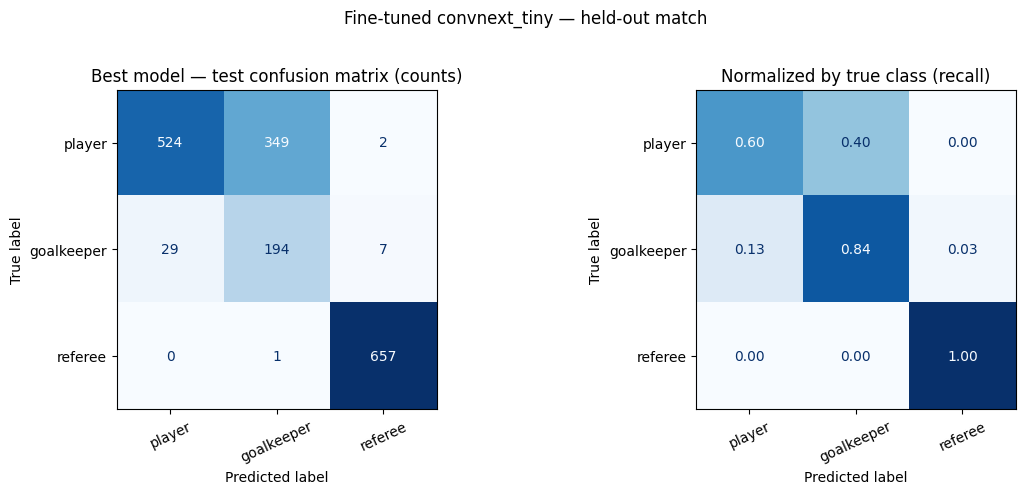

In [27]:
# Best model's confusion matrix based on saved held-out test predictions (no inference needed).
pred_file=OUT/'classification'/best_mode/'test_predictions.csv'
preds=pd.read_csv(pred_file)
assert {'label','prediction'}.issubset(preds.columns)
cm=confusion_matrix(preds['label'].astype(int),preds['prediction'].astype(int),labels=range(len(ROLE_NAMES)))
fig,axes=plt.subplots(1,2,figsize=(12,4.8))
ConfusionMatrixDisplay(cm,display_labels=ROLE_NAMES).plot(ax=axes[0],cmap='Blues',colorbar=False,values_format='d')
axes[0].set_title('Best model — test confusion matrix (counts)')
cm_norm=cm/cm.sum(axis=1,keepdims=True).clip(min=1)
ConfusionMatrixDisplay(cm_norm,display_labels=ROLE_NAMES).plot(ax=axes[1],cmap='Blues',colorbar=False,values_format='.2f')
axes[1].set_title('Normalized by true class (recall)')
for ax in axes: ax.tick_params(axis='x',rotation=25)
plt.suptitle(label_names[best_mode]+' — held-out match',y=1.02)
plt.tight_layout()
plt.savefig(OUT/'final_best_model_confusion_matrix.png',dpi=170,bbox_inches='tight')
plt.show()


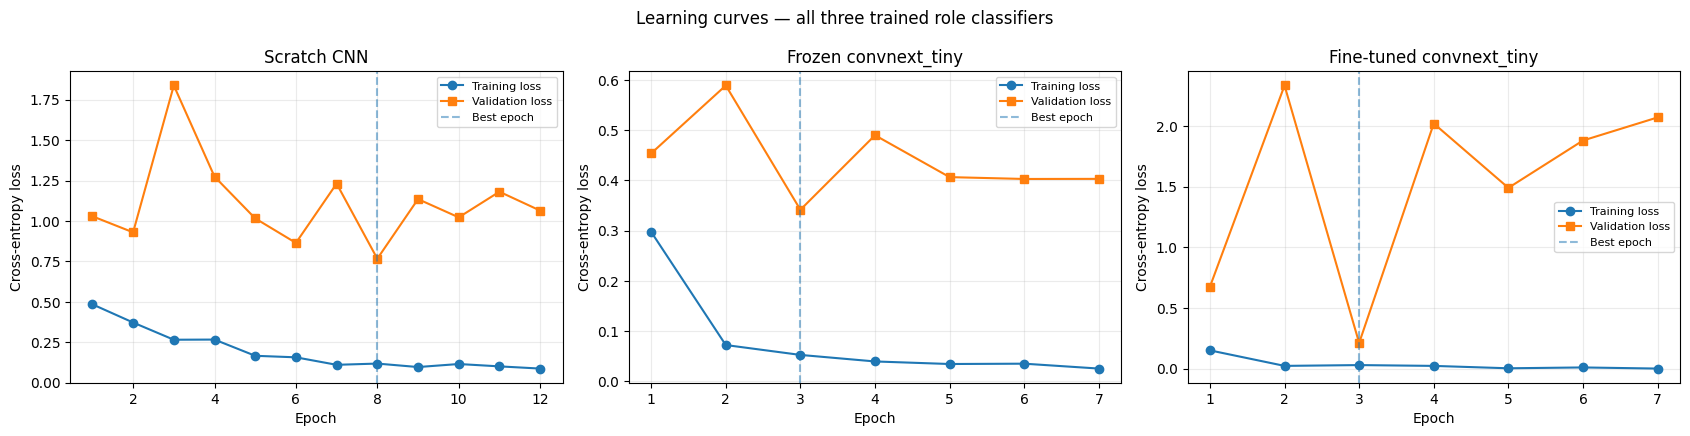

In [28]:
# Training vs validation LOSS learning curves from saved history.csv files.
fig,axs=plt.subplots(1,3,figsize=(17,4.4),sharey=False)
for ax,mode in zip(axs,role_order):
    h=pd.read_csv(OUT/'classification'/mode/'history.csv')
    ax.plot(h['epoch'],h['train_loss'],marker='o',label='Training loss')
    ax.plot(h['epoch'],h['val_loss'],marker='s',label='Validation loss')
    bi=h['val_loss'].idxmin()
    ax.axvline(h.loc[bi,'epoch'],linestyle='--',alpha=.5,label='Best epoch')
    ax.set_title(label_names[mode]);ax.set_xlabel('Epoch');ax.set_ylabel('Cross-entropy loss')
    ax.grid(alpha=.25);ax.legend(fontsize=8)
plt.suptitle('Learning curves — all three trained role classifiers')
plt.tight_layout();plt.savefig(OUT/'final_learning_curves_train_val_loss.png',dpi=170,bbox_inches='tight');plt.show()


## M2–M3 — Regularization experiment

The frozen ConvNeXt-Tiny classifier achieved approximately **99.37% training accuracy** and **89.09% validation accuracy**, indicating a substantial train–validation gap. Test stronger head regularization using dropout (`0.40`), weight decay (`0.01`), label smoothing (`0.05`), stronger augmentation, a learning rate of `1e-4`, cosine scheduling, and early stopping. Compare the new classifier with the baseline on validation accuracy, Macro-F1, and loss.


In [29]:
# This cell needs the notebook setup/models/data cells, but NO training cells rerun.
from copy import deepcopy
from torchvision import transforms
from torch import nn
from torch.utils.data import DataLoader
import math

reg_cfg = dict(epochs=14, patience=5, lr=1e-4, min_lr=1e-6,
               weight_decay=1e-2, dropout=0.40, label_smoothing=0.05)
REG_DIR = OUT/'classification'/'frozen_regularized'
REG_DIR.mkdir(parents=True,exist_ok=True)
base_ckpt = OUT/'classification'/'frozen'/'best.pt'
assert base_ckpt.is_file(), 'Cannot find frozen baseline checkpoint in the CURRENT OUT directory.'
assert BACKBONE=='convnext_tiny', f'Expected convnext_tiny; found {BACKBONE}'

# Small changes to the input crop; avoid aggressive random crops that remove the player.
reg_train_tf = transforms.Compose([
    transforms.Resize((CFG['image_size'],CFG['image_size'])),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=5, translate=(0.03,0.03), scale=(0.95,1.05)),
    transforms.ColorJitter(brightness=.20,contrast=.20,saturation=.15,hue=.03),
    transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD)
])

class RegularizedRoleDS(RoleDS):
    def __init__(self,frame):
        super().__init__(frame,training=False)
        self.tf=reg_train_tf

reg_train_loader=DataLoader(RegularizedRoleDS(crops[crops.split=='train']),
    batch_size=CFG['batch_size'],shuffle=True,num_workers=CFG['num_workers'],
    pin_memory=(DEVICE.type=='cuda'))

# Load the trained frozen model first; then insert dropout without losing head weights.
reg_net=build_role_model('frozen')
state=torch.load(base_ckpt,map_location='cpu',weights_only=False)
reg_net.load_state_dict(state['state_dict'])
original_head=reg_net.classifier[-1]
reg_net.classifier[-1]=nn.Sequential(nn.Dropout(reg_cfg['dropout']),original_head)
for p in reg_net.parameters():p.requires_grad=False
for p in reg_net.classifier[-1].parameters():p.requires_grad=True
reg_net=reg_net.to(DEVICE)

# Evaluation automatically disables dropout (model.eval), so comparisons are consistent.
reg_loss_fn=nn.CrossEntropyLoss(weight=class_weights,label_smoothing=reg_cfg['label_smoothing'])
reg_optimizer=torch.optim.AdamW(
    [p for p in reg_net.parameters() if p.requires_grad],
    lr=reg_cfg['lr'],weight_decay=reg_cfg['weight_decay'])
reg_scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(
    reg_optimizer,T_max=reg_cfg['epochs'],eta_min=reg_cfg['min_lr'])
print('Regularization setup ready:',reg_cfg)
print('Trainable parameters:',sum(p.numel() for p in reg_net.parameters() if p.requires_grad))


Regularization setup ready: {'epochs': 14, 'patience': 5, 'lr': 0.0001, 'min_lr': 1e-06, 'weight_decay': 0.01, 'dropout': 0.4, 'label_smoothing': 0.05}
Trainable parameters: 2307


In [30]:
# New HEAD-ONLY experiment: preserves the baseline checkpoints and detector.
reg_history=[]; reg_best_loss=float('inf'); reg_stale=0
for epoch in range(1,reg_cfg['epochs']+1):
    reg_net.eval()                    # frozen ConvNeXt feature extractor stays in eval mode
    reg_net.classifier[-1].train()    # activate dropout only in the classifier head
    total_loss=0.; total_n=0
    for xb,yb in reg_train_loader:
        xb=xb.to(DEVICE);yb=yb.to(DEVICE)
        reg_optimizer.zero_grad(set_to_none=True)
        logits=reg_net(xb)
        loss=reg_loss_fn(logits,yb)
        loss.backward()
        reg_optimizer.step()
        total_loss+=float(loss.item())*len(yb); total_n+=len(yb)
    val_metrics,_,_=evaluate_loader(reg_net,val_loader,nn.CrossEntropyLoss(weight=class_weights))
    # Train metrics on NON-augmented inputs for a fair comparison with validation.
    train_metrics,_,_=evaluate_loader(reg_net,make_loader('train',train=False),
                                     nn.CrossEntropyLoss(weight=class_weights))
    entry={'epoch':epoch,'train_loss_augmented':total_loss/max(total_n,1),
           'train_loss':train_metrics['loss'],'train_accuracy':train_metrics['accuracy'],
           'train_macro_f1':train_metrics['macro_f1'],
           'val_loss':val_metrics['loss'],'val_accuracy':val_metrics['accuracy'],
           'val_macro_f1':val_metrics['macro_f1'],
           'lr':reg_optimizer.param_groups[0]['lr']}
    reg_history.append(entry)
    if val_metrics['loss']<reg_best_loss-1e-4:
        reg_best_loss=val_metrics['loss'];reg_stale=0
        torch.save({'state_dict':reg_net.state_dict(),'backbone':BACKBONE,
                    'regularization':reg_cfg,'labels':ROLE_NAMES},REG_DIR/'best.pt')
    else:
        reg_stale+=1
    print(f"Epoch {epoch:02d} | train acc {entry['train_accuracy']:.3f} | "
          f"val acc {entry['val_accuracy']:.3f} | val F1 {entry['val_macro_f1']:.3f} | "
          f"val loss {entry['val_loss']:.4f} | lr {entry['lr']:.2g}")
    reg_scheduler.step()
    pd.DataFrame(reg_history).to_csv(REG_DIR/'history.csv',index=False)
    if reg_stale>=reg_cfg['patience']:
        print('Early stopping — no validation loss improvement');break
print('Regularized best checkpoint:',(REG_DIR/'best.pt').as_posix())


Epoch 01 | train acc 0.881 | val acc 0.681 | val F1 0.664 | val loss 0.2732 | lr 0.0001
Epoch 02 | train acc 0.884 | val acc 0.661 | val F1 0.640 | val loss 0.2806 | lr 9.9e-05
Epoch 03 | train acc 0.895 | val acc 0.659 | val F1 0.636 | val loss 0.2786 | lr 9.5e-05
Epoch 04 | train acc 0.909 | val acc 0.661 | val F1 0.639 | val loss 0.2817 | lr 8.9e-05
Epoch 05 | train acc 0.917 | val acc 0.661 | val F1 0.639 | val loss 0.2871 | lr 8.1e-05
Epoch 06 | train acc 0.919 | val acc 0.656 | val F1 0.633 | val loss 0.2844 | lr 7.2e-05
Early stopping — no validation loss improvement
Regularized best checkpoint: /kaggle/working/football_project_outputs/20261025T190854Z/classification/frozen_regularized/best.pt


,model,train_accuracy,val_accuracy,accuracy_gap,train_macro_f1,val_macro_f1,val_loss
0,Original frozen ConvNeXt,0.993717,0.890870,0.102847,0.982814,0.866083,0.3414
1,Regularized frozen ConvNeXt,0.880860,0.681253,0.199607,0.773281,0.663623,0.2732


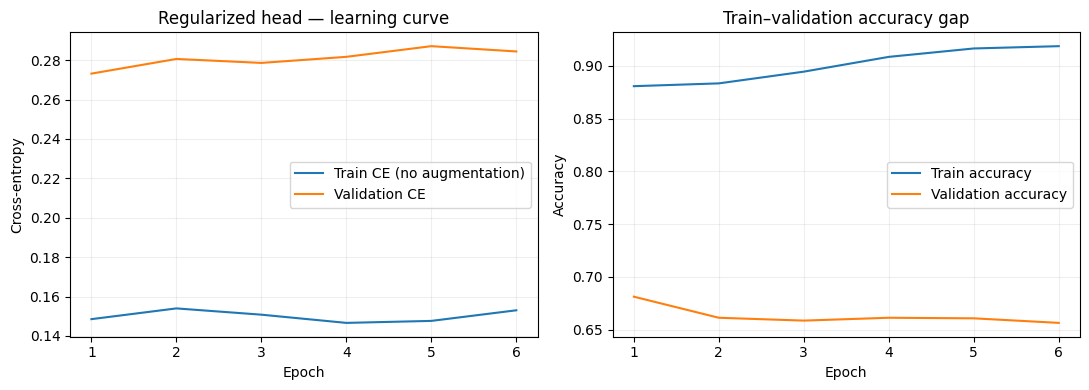

Validation-selected winner: Regularized frozen ConvNeXt
NOTE: A smaller gap alone is not sufficient if validation F1/accuracy declines.
No test-set selection performed. Original model and YOLO checkpoints are untouched.


In [31]:
# Validation-only comparison — do not load or inspect the test set to select a model.
baseline_net=build_role_model('frozen')
baseline_net.load_state_dict(torch.load(base_ckpt,map_location='cpu',weights_only=False)['state_dict'])
baseline_net=baseline_net.to(DEVICE).eval()
reg_best=build_role_model('frozen')
reg_head=reg_best.classifier[-1]
reg_best.classifier[-1]=nn.Sequential(nn.Dropout(reg_cfg['dropout']),reg_head)
reg_best.load_state_dict(torch.load(REG_DIR/'best.pt',map_location='cpu',weights_only=False)['state_dict'])
reg_best=reg_best.to(DEVICE).eval()

comparison=[]
for name,net in [('Original frozen ConvNeXt',baseline_net),('Regularized frozen ConvNeXt',reg_best)]:
    tr,_,_=evaluate_loader(net,make_loader('train',train=False),nn.CrossEntropyLoss(weight=class_weights))
    va,_,_=evaluate_loader(net,make_loader('val'),nn.CrossEntropyLoss(weight=class_weights))
    comparison.append({'model':name,'train_accuracy':tr['accuracy'],'val_accuracy':va['accuracy'],
                       'accuracy_gap':tr['accuracy']-va['accuracy'],
                       'train_macro_f1':tr['macro_f1'],'val_macro_f1':va['macro_f1'],
                       'val_loss':va['loss']})
reg_comparison=pd.DataFrame(comparison)
display(reg_comparison.style.format({k:'{:.2%}' for k in
    ['train_accuracy','val_accuracy','accuracy_gap','train_macro_f1','val_macro_f1']}).format({'val_loss':'{:.4f}'}))
reg_comparison.to_csv(REG_DIR/'validation_comparison.csv',index=False)

h=pd.read_csv(REG_DIR/'history.csv')
fig,axs=plt.subplots(1,2,figsize=(11,4))
axs[0].plot(h.epoch,h.train_loss,label='Train CE (no augmentation)')
axs[0].plot(h.epoch,h.val_loss,label='Validation CE')
axs[0].set(xlabel='Epoch',ylabel='Cross-entropy',title='Regularized head — learning curve');axs[0].legend()
axs[1].plot(h.epoch,h.train_accuracy,label='Train accuracy')
axs[1].plot(h.epoch,h.val_accuracy,label='Validation accuracy')
axs[1].set(xlabel='Epoch',ylabel='Accuracy',title='Train–validation accuracy gap');axs[1].legend()
for ax in axs:ax.grid(alpha=.2)
plt.tight_layout();plt.savefig(REG_DIR/'regularized_learning_curves.png',dpi=160);plt.show()

winner=reg_comparison.sort_values(['val_loss','val_macro_f1'],ascending=[True,False]).iloc[0]
print('Validation-selected winner:',winner['model'])
print('NOTE: A smaller gap alone is not sufficient if validation F1/accuracy declines.')
print('No test-set selection performed. Original model and YOLO checkpoints are untouched.')


## M2–M3 — Goalkeeper error analysis

The regularized classifier did not outperform the original frozen ConvNeXt-Tiny on validation accuracy or Macro-F1. Examine the baseline model's classwise validation results and confusion matrix, with particular attention to goalkeeper recall.


Original Frozen ConvNeXt — Validation
Accuracy: 0.8909
Macro-F1: 0.8661

Per-class Classification Report:
              precision    recall  f1-score   support

      player       0.93      0.88      0.91       875
  goalkeeper       0.85      0.70      0.77       323
     referee       0.86      0.99      0.92       653

    accuracy                           0.89      1851
   macro avg       0.88      0.86      0.87      1851
weighted avg       0.89      0.89      0.89      1851



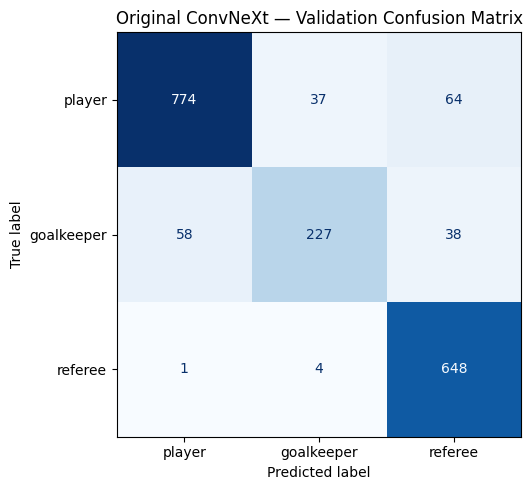

In [32]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd
import torch

# Load original best Frozen ConvNeXt
best_model = build_role_model("frozen")

checkpoint = torch.load(
    OUT / "classification" / "frozen" / "best.pt",
    map_location="cpu",
    weights_only=False
)

best_model.load_state_dict(checkpoint["state_dict"])
best_model = best_model.to(DEVICE).eval()

# Evaluate on validation data only
val_metrics, y_true, probabilities = evaluate_loader(
    best_model,
    make_loader("val"),
    torch.nn.CrossEntropyLoss(weight=class_weights)
)

y_pred = probabilities.argmax(axis=1)

# Print overall metrics
print("Original Frozen ConvNeXt — Validation")
print("Accuracy:", round(val_metrics["accuracy"], 4))
print("Macro-F1:", round(val_metrics["macro_f1"], 4))

# Print per-class metrics
print("\nPer-class Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(ROLE_NAMES))),
    target_names=ROLE_NAMES,
    zero_division=0
))

# Calculate confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(ROLE_NAMES)))
)

# Plot confusion matrix using Matplotlib
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=ROLE_NAMES
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Original ConvNeXt — Validation Confusion Matrix")

plt.tight_layout()
plt.show()


### Validation-based goalkeeper score adjustment

Multiply the predicted goalkeeper score by a range of candidate weights, then measure validation accuracy, Macro-F1, and classwise recall. Expand the search from `1.0–2.5` to `1.0–4.0` and select the weight with the highest validation Macro-F1. The selected weight is **2.70**; the network parameters remain unchanged.


In [33]:

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, recall_score

# Use probabilities and labels already computed above
y_true = np.asarray(y_true)
probs = np.asarray(probabilities)

gk_idx = ROLE_NAMES.index("goalkeeper")

results = []

# Adjust goalkeeper probability on validation data only
for weight in np.arange(1.0, 2.51, 0.05):
    adjusted = probs.copy()
    adjusted[:, gk_idx] *= weight

    predictions = adjusted.argmax(axis=1)

    results.append({
        "GK_weight": round(float(weight), 2),
        "Accuracy": accuracy_score(y_true, predictions),
        "Macro_F1": f1_score(
            y_true, predictions, average="macro"
        ),
        "GK_Recall": recall_score(
            y_true == gk_idx,
            predictions == gk_idx,
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

# Select using validation Macro-F1
best_row = results_df.loc[
    results_df["Macro_F1"].idxmax()
]

display(
    results_df.sort_values(
        "Macro_F1", ascending=False
    ).head(10)
)

print("\nBest validation operating point:")
print(best_row)

print("\nOriginal Macro-F1:", round(
    f1_score(y_true, probs.argmax(axis=1), average="macro"), 4
))
print("Adjusted Macro-F1:", round(best_row["Macro_F1"], 4))


,GK_weight,Accuracy,Macro_F1,GK_Recall
30,2.50,0.891950,0.874140,0.823529
29,2.45,0.891410,0.873361,0.820433
14,1.70,0.893031,0.873068,0.780186
15,1.75,0.892491,0.872905,0.786378
19,1.95,0.891950,0.872803,0.798762
28,2.40,0.890870,0.872531,0.817337
17,1.85,0.891950,0.872513,0.789474
27,2.35,0.890870,0.872359,0.814241
16,1.80,0.891950,0.872283,0.786378
26,2.30,0.890870,0.872174,0.811146



Best validation operating point:
GK_weight    2.500000
Accuracy     0.891950
Macro_F1     0.874140
GK_Recall    0.823529
Name: 30, dtype: float64

Original Macro-F1: 0.8661
Adjusted Macro-F1: 0.8741


Best GK weight: 2.7


,GK_weight,Accuracy,Macro_F1,Player_Recall,GK_Recall,Referee_Recall
34,2.70,0.893031,0.875857,0.851429,0.832817,0.978560
35,2.75,0.891950,0.874638,0.849143,0.832817,0.978560
32,2.60,0.891950,0.874307,0.851429,0.826625,0.978560
33,2.65,0.891950,0.874307,0.851429,0.826625,0.978560
30,2.50,0.891950,0.874140,0.852571,0.823529,0.978560
31,2.55,0.891950,0.874140,0.852571,0.823529,0.978560
38,2.90,0.890870,0.873761,0.845714,0.839009,0.977029
37,2.85,0.890870,0.873761,0.845714,0.839009,0.977029
36,2.80,0.890870,0.873422,0.846857,0.832817,0.978560
29,2.45,0.891410,0.873361,0.852571,0.820433,0.978560


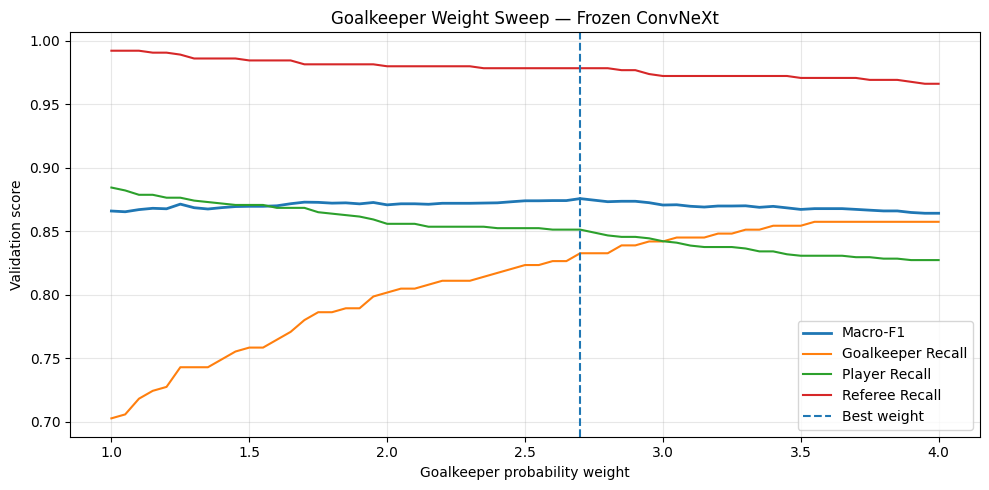

In [34]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, recall_score

gk_idx = ROLE_NAMES.index("goalkeeper")
records = []

for weight in np.arange(1.0, 4.01, 0.05):
    adjusted = probabilities.copy()
    adjusted[:, gk_idx] *= weight

    pred = adjusted.argmax(axis=1)

    class_recall = recall_score(
        y_true, pred,
        labels=list(range(len(ROLE_NAMES))),
        average=None,
        zero_division=0
    )

    records.append({
        "GK_weight": round(float(weight), 2),
        "Accuracy": accuracy_score(y_true, pred),
        "Macro_F1": f1_score(
            y_true, pred,
            average="macro"
        ),
        "Player_Recall": class_recall[ROLE_NAMES.index("player")],
        "GK_Recall": class_recall[gk_idx],
        "Referee_Recall": class_recall[ROLE_NAMES.index("referee")]
    })

sweep = pd.DataFrame(records)

best = sweep.loc[sweep["Macro_F1"].idxmax()]
BEST_GK_WEIGHT = float(best["GK_weight"])

print("Best GK weight:", BEST_GK_WEIGHT)
display(sweep.sort_values("Macro_F1", ascending=False).head(10))

plt.figure(figsize=(10, 5))
plt.plot(sweep.GK_weight, sweep.Macro_F1, label="Macro-F1", linewidth=2)
plt.plot(sweep.GK_weight, sweep.GK_Recall, label="Goalkeeper Recall")
plt.plot(sweep.GK_weight, sweep.Player_Recall, label="Player Recall")
plt.plot(sweep.GK_weight, sweep.Referee_Recall, label="Referee Recall")
plt.axvline(BEST_GK_WEIGHT, linestyle="--", label="Best weight")
plt.xlabel("Goalkeeper probability weight")
plt.ylabel("Validation score")
plt.title("Goalkeeper Weight Sweep — Frozen ConvNeXt")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Held-out evaluation of the goalkeeper adjustment

Apply the validation-selected goalkeeper weight of **2.70** to the held-out test predictions. Compare the original and adjusted decision rules using accuracy, Macro-F1, goalkeeper recall, and confusion matrices. Accuracy changes from **89.96% to 91.09%**, Macro-F1 from **80.47% to 85.05%**, and goalkeeper recall from **40.00% to 60.43%**. The adjustment improves goalkeeper recall with a trade-off in player recall.


,Model,Accuracy,Macro-F1,GK Recall
0,Original Frozen ConvNeXt,0.899603,0.804707,0.400000
1,Adjusted Frozen ConvNeXt (GK=2.70),0.910947,0.850472,0.604348



Adjusted Model — Test Classification Report
              precision    recall  f1-score   support

      player       0.92      0.92      0.92       875
  goalkeeper       0.70      0.60      0.65       230
     referee       0.97      1.00      0.98       658

    accuracy                           0.91      1763
   macro avg       0.86      0.84      0.85      1763
weighted avg       0.91      0.91      0.91      1763



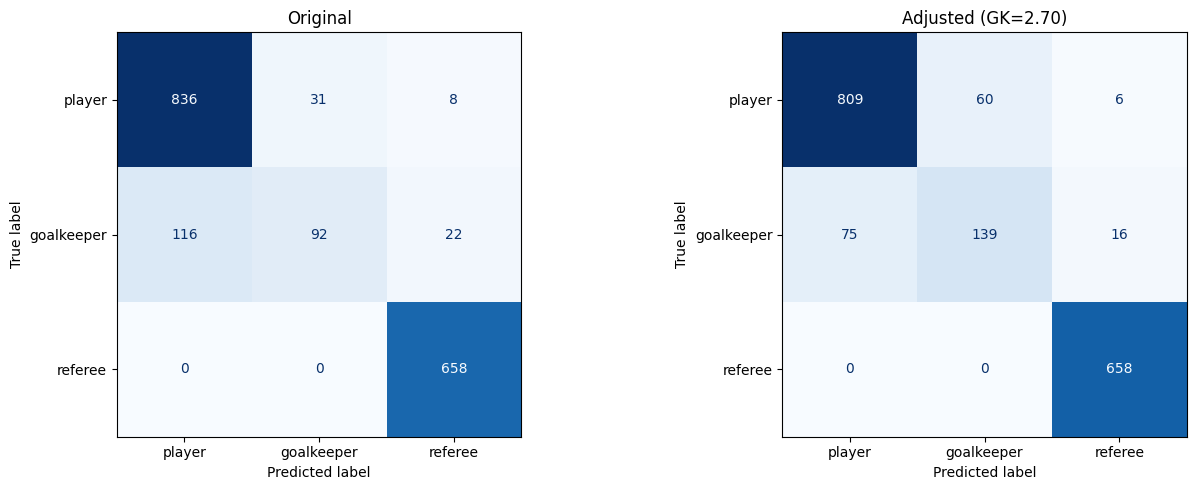

In [35]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

# Locked weight selected using validation only
BEST_GK_WEIGHT = 2.70
gk_idx = ROLE_NAMES.index("goalkeeper")

# Evaluate saved best model on held-out test data
test_metrics, y_test, test_probs = evaluate_loader(
    best_model,
    make_loader("test"),
    torch.nn.CrossEntropyLoss(weight=class_weights)
)

y_test = np.asarray(y_test)
test_probs = np.asarray(test_probs)

# Original predictions
original_pred = test_probs.argmax(axis=1)

# Adjusted predictions
adjusted_probs = test_probs.copy()
adjusted_probs[:, gk_idx] *= BEST_GK_WEIGHT
adjusted_pred = adjusted_probs.argmax(axis=1)

# Comparison
results = pd.DataFrame([
    {
        "Model": "Original Frozen ConvNeXt",
        "Accuracy": accuracy_score(y_test, original_pred),
        "Macro-F1": f1_score(y_test, original_pred, average="macro"),
        "GK Recall": recall_score(
            y_test == gk_idx, original_pred == gk_idx
        )
    },
    {
        "Model": "Adjusted Frozen ConvNeXt (GK=2.70)",
        "Accuracy": accuracy_score(y_test, adjusted_pred),
        "Macro-F1": f1_score(y_test, adjusted_pred, average="macro"),
        "GK Recall": recall_score(
            y_test == gk_idx, adjusted_pred == gk_idx
        )
    }
])

display(results)

print("\nAdjusted Model — Test Classification Report")
print(classification_report(
    y_test,
    adjusted_pred,
    labels=list(range(len(ROLE_NAMES))),
    target_names=ROLE_NAMES,
    zero_division=0
))

# Test confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, predictions, title in zip(
    axes,
    [original_pred, adjusted_pred],
    ["Original", "Adjusted (GK=2.70)"]
):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        labels=list(range(len(ROLE_NAMES))),
        display_labels=ROLE_NAMES,
        cmap="Blues",
        values_format="d",
        colorbar=False,
        ax=ax
    )
    ax.set_title(title)

plt.tight_layout()
plt.show()


### Final classifier configuration

The selected model is the **frozen pretrained ConvNeXt-Tiny** with a goalkeeper score multiplier of **2.70**, chosen using validation Macro-F1. Save the model selection, adjustment weight, and held-out test metrics in the final configuration file. The reported performance reflects the test match evaluated here; additional matches would be needed to assess broader generalization.


In [36]:
import json

final_config = {
    "model": "Frozen ConvNeXt-Tiny",
    "goalkeeper_weight": 2.70,
    "selection_metric": "Validation Macro-F1",
    "test_accuracy": 0.910947,
    "test_macro_f1": 0.850472,
    "test_goalkeeper_recall": 0.604348
}

(OUT / "final_classifier_config.json").write_text(
    json.dumps(final_config, indent=2)
)

print("Final classifier configuration saved.")

Final classifier configuration saved.
